# Data Preparation

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = sqlite3.connect("../data/hockey.db")
q = lambda sql: pd.read_sql(sql, con)
sql_file = lambda name: q(open(f"../sql/{name}").read())

sns.set_theme(style="whitegrid")

## 1. Data Integration

In this section we join tables so that each row carries information from more than one source. The rubric asks for two things, and we document both:

- **Matching entities between sources**: the key used to link two tables.
- **Conversion of formats**: turning raw fields into values a model can use.

### 1.1 Coach profile

Query: [`sql/coach_profile.sql`](../sql/coach_profile.sql). One row per coach stint (`coachID`, `year`, `tmID`, `lgID`, `stint`), for **all leagues**, with the person's details from `Master`.

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `Coaches` | `Master` | `coachID` | birth date, `playerID`, `firstNHL` |

- We use a **left join** with `Coaches` as the driving table, so every coaching stint is kept even if the person were missing from `Master`.
- The result has **1,741 rows**, the same as `Coaches`. Every coach finds a match, and no `coachID` appears twice in `Master`, so the join neither loses nor duplicates rows.
- We keep **all leagues** (NHL, WHA, NHA, PCHA, WCHL), not only the NHL, so that a coach's experience can later include seasons coached outside the NHL. `lgID` is kept so we can filter to the NHL when building targets, and to join with `Teams` later.

#### 1.1.1 Age at season start (format conversion)

`Master` stores the birth date in three separate columns (`birthYear`, `birthMon`, `birthDay`). We convert them into one number: the coach's **age at the start of the season**.

- **Reference date:** 1 August of `year`. In this dataset `year` is the season's starting year (2005 = 2005-06), so 1 August is before the season begins, and the age is known at prediction time.
- **Birthday rule:** if the birthday falls after 1 August, the coach has not turned the new age yet, so we subtract one year.
- **Missing month or day:** we assume 1 August, the same as the reference date. The age then becomes simply `year − birthYear`, which is wrong by at most one year.
- **Missing year:** the age is left missing (`<NA>`). It is not imputed here; that is handled in the *Missing values* section.

In [2]:
import datetime

coaches = sql_file("coach_profile.sql")

def calculate_age(row):
    if pd.isna(row["birthYear"]):
        return pd.NA
    
    birth_year = int(row["birthYear"])
    birth_month = 8 if pd.isna(row["birthMon"]) else int(row["birthMon"])
    birth_day = 1 if pd.isna(row["birthDay"]) else int(row["birthDay"])
    
    birth_date = datetime.date(
        birth_year,
        birth_month,
        birth_day
    )

    reference_date = datetime.date(
        int(row["year"]),
        8,
        1
    )

    age = reference_date.year - birth_date.year

    if (birth_date.month, birth_date.day) > (
        reference_date.month,
        reference_date.day
    ):
        age -= 1

    return age

coaches["age"] = coaches.apply(calculate_age, axis=1)
coaches["age"] = coaches["age"].astype("Int64")

#### 1.1.2 Former player (format conversion)

`Master` only tells us *whether* a coach has a player record. We turn that into two 0/1 features:

| Feature | Rule | Meaning |
|---|---|---|
| `former_player` | `playerID` is not null | played in any league in the data |
| `former_nhl_player` | `firstNHL` is not null | played in the NHL |

Here a null does **not** mean "unknown": it means the person never played. So these flags have no missing values.

After building the features we drop the raw columns (`birthYear`, `birthMon`, `birthDay`, `playerID`, `firstNHL`), which are not useful to a model as they are.

In [3]:
import numpy as np
coaches["former_player"] = np.where(
    coaches["playerID"].isna(), 0, 1
)
coaches["former_nhl_player"] = np.where(
    coaches["firstNHL"].isna(), 0, 1
)

In [4]:
profile = coaches.drop(["birthYear", "birthMon", "birthDay", "playerID", "firstNHL"], axis = 1)

#### 1.1.3 Checks on the coach profile

In [5]:
younger_coach = profile["age"].min()
oldest_coach = profile["age"].max()
print(f'The youngest coach as age: {younger_coach}. The Oldest coach as age: {oldest_coach}')

The youngest coach as age: 22. The Oldest coach as age: 74


In [6]:
no_age = profile["age"].isnull().sum()
print(f'There is {no_age} missing values')

null_age = profile[profile["age"].isnull()]
grouped_no_age = null_age.groupby('lgID').size().reset_index(name="count").sort_values("count",ascending=False)

print(grouped_no_age)

There is 60 missing values
   lgID  count
1   NHL     25
0   NHA     19
3  WCHL     10
2  PCHA      3
4   WHA      3


In [7]:
total = profile["former_player"].count()
former_player = (profile["former_player"] == 1).sum()

percentage = former_player / total * 100

print(f'The percentage of coaches that were former players is {percentage:.2f}%')

total = profile["former_nhl_player"].count()
former_nhl_player = (profile["former_nhl_player"] == 1).sum()

percentage = former_nhl_player / total * 100

print(f'The percentage of coaches that were former players is {percentage:.2f}%')


The percentage of coaches that were former players is 65.54%
The percentage of coaches that were former players is 63.12%


**Results**

- **Age range: 22 to 74.** Both are real cases, not data errors. The youngest is a player-coach in the NHA in 1916, when teams often had a player also coaching. The oldest is Al Arbour, who came back for one game with the Islanders in 2007. The youngest coach in the NHL itself is 25 (1979). No age is impossible, so no value is removed (validity).
- **60 stints (3.4%) have no age**, from 27 coaches with no `birthYear`. They come mostly from the early leagues (NHA, PCHA, WCHL). The 25 NHL rows are all from before 1940, so this gap should almost disappear after the era selection. We re-check it there (completeness).
- **Missing day or month only:** 30 more stints have a birth year but no month or day; their age uses the approximation described above.
- **Former players:** 65.5% of coaching stints are by former players, and 63.1% by former NHL players. These percentages count **stints (rows)**, not distinct coaches, so coaches with long careers count more than once.

### 1.2 Coach History

Career features for each coach, built from [`sql/coach_history.sql`](../sql/coach_history.sql): one row per coach per season (all leagues), with the season's games, wins, losses, ties and playoff games summed over all the coach's stints in that season.

**Rule: only seasons before *t*.** Predictions are made the day before season *t* starts, so a coach's history for season *t* may only use seasons up to *t-1*. Anything from season *t* itself (its wins, its playoff games) is not known yet and would be leakage.

| Source | Key | What we bring in |
|---|---|---|
| `Coaches` (aggregated per season) | `coachID` | games, wins, ties and playoff games of every earlier season |

#### 1.2.1 Sort by coach and year

The running totals below are computed in row order, so each coach's seasons must be in chronological order first.

In [8]:
history = sql_file("coach_history.sql")

history = history.sort_values(by=["coachID", "year"], ascending=[True, True])

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0


#### 1.2.2 How a tie counts

A tie counts as **half a win**: win% = (wins + ½·ties) / games. This matches how hockey standings value a tie (1 point out of 2) and is consistent with `pts_pct` in the team features. It is expressed as a fraction (0–1), the same scale as `pts_pct`.

In [9]:
history["win_pct"] = (history["w"] + 0.5 * history["t"])/history["g"]

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571


#### 1.2.3 Running totals (up to and including season *t*)

For each coach, a cumulative sum over his seasons in chronological order of games, wins, ties, playoff games and number of seasons. The sum is computed **within each coach** (grouped by `coachID`), so one coach's career never carries over into the next coach's rows.

At this point the totals still **include** season *t*, so they cannot be used as features yet.

In [10]:
count_columns = ["g", "w", "t", "l", "postg", "seasons_before"]

history["seasons_before"] = 1

career_columns = [
    "games_before",
    "wins_before",
    "ties_before",
    "losses_before",
    "postgames_before",
    "seasons_before"
]

history[career_columns] = history.groupby("coachID")[count_columns].cumsum()

print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct  \
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857   
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429   
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606   
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286   
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571   

   seasons_before  games_before  wins_before  ties_before  losses_before  \
0               1          70.0         27.0         15.0           28.0   
1               2         140.0         39.0         22.0           79.0   
2               3         173.0         55.0         27.0           91.0   
3               4         243.0         80.0         35.0          128.0   
4               5         313.0        106.0         50.0          157.0   

   postgames_before  
0               7.0  
1               7.0  
2       

#### 1.2.4 Move the totals to "before season *t*"

Each running total is shifted down by one season within the same coach, so the row for season *t* holds the totals **up to season *t-1***. Career totals do not need consecutive seasons: if a coach skipped years, the shifted value is still the sum of all his earlier seasons.

**First season of each coach (rookie coach).** After the shift there is nothing before it, but the meaning differs per feature:

| Feature | First season | Why |
|---|---|---|
| seasons, games, wins, ties, playoff games before *t* | **0** | the coach really had zero |
| `win_career_pct` | **missing** | 0 / 0 is undefined; a rookie has no record, which is not the same as a 0% record. Handled in *Missing values* |
| `is_rookie_coach` | **1** | flags the rows where the career win% is missing for this reason |

In [11]:
history[career_columns] = history.groupby("coachID")[career_columns].shift(1).fillna(0.0)



history["win_before_pct"] = (history["wins_before"] + 0.5 * history["ties_before"])/history["games_before"]
history["is_rookie_coach"] = np.where(history["games_before"] == 0.0, 1, 0)
print(history.head())

     coachID  year lgID  n_stints     g     w     l     t  postg   win_pct  \
0  abelsi01c  1952  NHL         1  70.0  27.0  28.0  15.0    7.0  0.492857   
1  abelsi01c  1953  NHL         1  70.0  12.0  51.0   7.0    0.0  0.221429   
2  abelsi01c  1957  NHL         1  33.0  16.0  12.0   5.0    4.0  0.560606   
3  abelsi01c  1958  NHL         1  70.0  25.0  37.0   8.0    0.0  0.414286   
4  abelsi01c  1959  NHL         1  70.0  26.0  29.0  15.0    6.0  0.478571   

   seasons_before  games_before  wins_before  ties_before  losses_before  \
0             0.0           0.0          0.0          0.0            0.0   
1             1.0          70.0         27.0         15.0           28.0   
2             2.0         140.0         39.0         22.0           79.0   
3             3.0         173.0         55.0         27.0           91.0   
4             4.0         243.0         80.0         35.0          128.0   

   postgames_before  win_before_pct  is_rookie_coach  
0               0.0

#### 1.2.5 Clean up

We drop the season's own results (`g`, `w`, `l`, `t`, `postg`, `win_pct`). They describe season *t* itself, so keeping them as features would be leakage. They are still available from the SQL if needed for the targets.

In [12]:
history = history.drop(["g", "w", "l", "t", "postg", "win_pct", "n_stints"], axis = 1)

print(history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  
0                1  
1                0  
2                0  
3                0  
4                0  


#### 1.2.6 Result

One row per (coach, season) with the coach's career up to the previous season. It is not attached to teams yet: that happens when building the targets, where we choose which coach describes each team-season.

In [13]:
is_rookie = (history["is_rookie_coach"] == 1).sum()

print(f'There is {is_rookie} values')

print(history.head())

There is 384 values
     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  
0                1  
1                0  
2                0  
3                0  
4                0  


### 1.3 Awards

Awards from [`sql/coach_award.sql`](../sql/coach_award.sql): one row per coach-season in which the coach won an award, with the number of awards. **All award types are counted** (Jack Adams, Baldwin, Schmertz, First/Second Team All-Star), consistent with keeping all leagues for coaching experience.

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `AwardsCoaches` | coach history | (`coachID`, `year`) | number of awards won that season |

**Leakage rule:** an award for season *t* is given after season *t* ends, so it only counts from season *t+1*. We apply the same running total + shift within each coach as for the career features.

In [14]:
awards = sql_file("coach_award.sql")

print(awards.head())

      coachID  year  awards_won
0  adamsja01c  1936           1
1  adamsja01c  1942           1
2  adamsja01c  1944           1
3  arboual01c  1978           1
4  barbebi01c  2000           1


#### 1.3.1 Merge

Left join onto the coach history, so every coach-season is kept. A season with no award has no row in `AwardsCoaches`, so after the join it is NULL; here NULL means "no award", not "unknown", so it becomes 0.

In [15]:
merged_history = pd.merge(history, awards, on=["coachID", "year"], how="left")

merged_history["awards_won"] = merged_history["awards_won"].fillna(0)
print(merged_history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  awards_won  
0                1         0.0  
1                0         0.0  
2                0         0.0  
3                0         0.0  
4          

#### 1.3.2 Awards Before

In [16]:
merged_history["awards_before"] = 0

merged_history["awards_before"] = merged_history.groupby("coachID")["awards_won"].cumsum()

merged_history["awards_before"] = merged_history.groupby("coachID")["awards_before"].shift(1).fillna(0)

print(merged_history.head())

     coachID  year lgID  seasons_before  games_before  wins_before  \
0  abelsi01c  1952  NHL             0.0           0.0          0.0   
1  abelsi01c  1953  NHL             1.0          70.0         27.0   
2  abelsi01c  1957  NHL             2.0         140.0         39.0   
3  abelsi01c  1958  NHL             3.0         173.0         55.0   
4  abelsi01c  1959  NHL             4.0         243.0         80.0   

   ties_before  losses_before  postgames_before  win_before_pct  \
0          0.0            0.0               0.0             NaN   
1         15.0           28.0               7.0        0.492857   
2         22.0           79.0               7.0        0.357143   
3         27.0           91.0              11.0        0.395954   
4         35.0          128.0              11.0        0.401235   

   is_rookie_coach  awards_won  awards_before  
0                1         0.0            0.0  
1                0         0.0            0.0  
2                0         0.0  

#### 1.3.3 Checks on the awards

1. **Row count:** the left join must not add or remove coach-seasons.
2. **Awards lost in the join:** awards whose (coach, season) does not exist in `Coaches`. We expect exactly one: Dave Tippett, Jack Adams 2009, with no 2009 season in `Coaches` (data quality: accuracy). Losing it does not matter for the features, because there is no season after 2009 in which it could count.
3. **Rookie coaches** (first season) must have `awards_before == 0`. A positive value means a previous coach's awards leaked into the next coach's first row.
4. **Never goes down:** within a coach, `awards_before` can only stay the same or grow.
5. **Hand check:** Dick Irvin (`irvindi01c`, the most awarded coach). Each award in `awards_won` must appear one season later in `awards_before`.

In [17]:
print(f"1. rows: history = {len(history)}, merged = {len(merged_history)} ->",
      "OK" if len(history) == len(merged_history) else "FAIL")

lost = awards.merge(history[["coachID", "year"]], on=["coachID", "year"], how="left", indicator=True)
lost = lost[lost["_merge"] == "left_only"]
print(f"2. awards with no matching coach-season: {len(lost)}")
print(lost[["coachID", "year", "awards_won"]].to_string(index=False))

rookies = merged_history[merged_history["is_rookie_coach"] == 1]
bad_rookies = rookies[rookies["awards_before"] > 0]
print(f"3. rookie coaches with awards_before > 0: {len(bad_rookies)} ->", "OK" if len(bad_rookies) == 0 else "FAIL")
print(bad_rookies[["coachID", "year", "awards_before"]].head().to_string(index=False))

goes_down = merged_history.groupby("coachID")["awards_before"].diff() < 0
print(f"4. rows where awards_before goes down: {goes_down.sum()} ->", "OK" if goes_down.sum() == 0 else "FAIL")

print("5. Dick Irvin: each award should appear one season later in awards_before")
print(merged_history.loc[merged_history["coachID"] == "irvindi01c", ["year", "awards_won", "awards_before"]].head(12).to_string(index=False))

1. rows: history = 1729, merged = 1729 -> OK
2. awards with no matching coach-season: 1
   coachID  year  awards_won
tippeda01c  2009           1
3. rookie coaches with awards_before > 0: 0 -> OK
Empty DataFrame
Columns: [coachID, year, awards_before]
Index: []
4. rows where awards_before goes down: 0 -> OK
5. Dick Irvin: each award should appear one season later in awards_before
 year  awards_won  awards_before
 1928         0.0            0.0
 1930         1.0            0.0
 1931         1.0            1.0
 1932         1.0            2.0
 1933         1.0            3.0
 1934         1.0            4.0
 1935         0.0            5.0
 1936         0.0            5.0
 1937         0.0            5.0
 1938         0.0            5.0
 1939         0.0            5.0
 1940         1.0            5.0


#### 1.3.4 Clean Up

In [18]:
merged_history = merged_history.drop(["awards_won"], axis = 1)

### 1.4 Tenure

**Tenure** = number of **consecutive** seasons the coach has led **this franchise** before season *t*. Unlike the career features, it is counted per franchise and a gap breaks the streak (a coach who comes back after years away starts again from 0).

Query: [`sql/coach_tenure.sql`](../sql/coach_tenure.sql), one row per (coach, franchise, season).

| Source | Target | Key | What we bring in |
|---|---|---|---|
| `Coaches` | `Teams` | (`year`, `tmID`, `lgID`) | `franchID` |

We use `franchID`, not `tmID`, because teams relocate and change code (28 franchises used more than one `tmID`); a relocated team is still the same job. Two stints of the same coach with the same franchise in one season count as one season.

In [19]:
tenure = sql_file("coach_tenure.sql")

print(tenure.head())

      coachID  year lgID franchID
0   boondi01c  1909  NHA      MTW
1   hareto01c  1909  NHA      BKN
2  lavioja01c  1909  NHA      TBS
3  stuarbr02c  1909  NHA      STE
4  triheha01c  1909  NHA      MOS


#### 1.4.1 Streaks

**The lockout.** There was no 2004 season, so a coach who led the same team in 2003 and 2005 never left. Comparing calendar years would wrongly start a new streak in 2005. Instead, each season gets a **season number** (its position among the seasons that exist in `Teams`), so 2003 and 2005 are consecutive, and any real gap is still detected.

**Counting the streak**, within each (coach, franchise), sorted by year:
1. Mark the rows that **start a new streak**: the first season with that franchise, or a season whose number is not the previous one + 1.
2. A **running count** of those marks gives each streak an id.
3. Within each streak, number the seasons from 0: that number is `tenure_before`, the seasons already completed with this franchise **before** season *t* (0 in the first season).

**Decisions.** A partial season (e.g. a coach hired mid-season, including the 9 interim stints) counts as a full season of tenure. The Detroit 1998 co-coaches each get the season.

In [20]:
tenure["season_number"] = (
    tenure["year"].ne(tenure["year"].shift()).cumsum()
)

print(tenure.head())

      coachID  year lgID franchID  season_number
0   boondi01c  1909  NHA      MTW              1
1   hareto01c  1909  NHA      BKN              1
2  lavioja01c  1909  NHA      TBS              1
3  stuarbr02c  1909  NHA      STE              1
4  triheha01c  1909  NHA      MOS              1


In [21]:
tenure = tenure.sort_values(["coachID", "franchID", "year"]).copy()

previous_season = tenure.groupby(["coachID", "franchID"])["season_number"].shift(1)
tenure["new_streak"] = previous_season.isna() | (tenure["season_number"] != previous_season + 1)

tenure["streak_id"] = tenure.groupby(["coachID", "franchID"])["new_streak"].cumsum()

tenure["tenure_before"] = tenure.groupby(["coachID", "franchID", "streak_id"]).cumcount()

print(tenure.head())

       coachID  year lgID franchID  season_number  new_streak  streak_id  \
369  abelsi01c  1952  NHL      CHI             44        True          1   
375  abelsi01c  1953  NHL      CHI             45       False          1   
401  abelsi01c  1957  NHL      DET             49        True          1   
409  abelsi01c  1958  NHL      DET             50       False          1   
416  abelsi01c  1959  NHL      DET             51       False          1   

     tenure_before  
369              0  
375              1  
401              0  
409              1  
416              2  


#### 1.4.2 Checks on the tenure

1. **Row count:** one row per (coach, franchise, season). Expected **1,736**: `Coaches` has 1,741 stints, and in 5 cases a coach had two stints with the same franchise in the same season.
2. **Streak starts:** every streak starts at tenure 0, so the number of rows with `tenure_before == 0` must equal the number of distinct (coach, franchise) pairs plus the comebacks after a real gap. An independent count finds **72** comebacks (gaps other than the 2004 lockout).
3. **Lockout:** a coach who led the same franchise in 2003 and in 2005 has an unbroken streak (there was no 2004 season), so his 2005 tenure must be his 2003 tenure + 1, never 0. There are **22** such cases.
4. **Hand check:** Al Arbour (`arboual01c`) with the Islanders (`NYI`). His tenure must go back to 0 in **1988** and in **2007**, when he came back after years away.
5. **Consistency with the career table:** a coach cannot have been with one franchise longer than his whole career, so `tenure_before <= seasons_before` in every row.

In [22]:

print(f"1. rows: {len(tenure)} (expected 1736) ->", "OK" if len(tenure) == 1736 else "FAIL")

n_pairs = tenure[["coachID", "franchID"]].drop_duplicates().shape[0]
n_starts = (tenure["tenure_before"] == 0).sum()
print(f"2. streak starts: {n_starts}, expected {n_pairs} pairs + 72 comebacks = {n_pairs + 72} ->",
      "OK" if n_starts == n_pairs + 72 else "FAIL")

t03 = tenure[tenure["year"] == 2003][["coachID", "franchID", "tenure_before"]]
t05 = tenure[tenure["year"] == 2005][["coachID", "franchID", "tenure_before"]]
lockout = t03.merge(t05, on=["coachID", "franchID"], suffixes=("_2003", "_2005"))
broken = lockout[lockout["tenure_before_2005"] != lockout["tenure_before_2003"] + 1]
print(f"3. lockout cases: {len(lockout)}, streak wrongly broken in {len(broken)} ->",
      "OK" if len(broken) == 0 else "FAIL")
print(broken.head().to_string(index=False))

print("4. Al Arbour with NYI:")
print(tenure.loc[(tenure["coachID"] == "arboual01c") & (tenure["franchID"] == "NYI"),
                 ["year", "tenure_before"]].to_string(index=False))

both = tenure.merge(merged_history[["coachID", "year", "seasons_before"]], on=["coachID", "year"], how="left")
too_long = both[both["tenure_before"] > both["seasons_before"]]
print(f"5. rows with tenure_before > seasons_before: {len(too_long)} ->", "OK" if len(too_long) == 0 else "FAIL")

1. rows: 1736 (expected 1736) -> OK


2. streak starts: 688, expected 616 pairs + 72 comebacks = 688 -> OK
3. lockout cases: 22, streak wrongly broken in 0 -> OK
Empty DataFrame
Columns: [coachID, franchID, tenure_before_2003, tenure_before_2005]
Index: []
4. Al Arbour with NYI:
 year  tenure_before
 1973              0
 1974              1
 1975              2
 1976              3
 1977              4
 1978              5
 1979              6
 1980              7
 1981              8
 1982              9
 1983             10
 1984             11
 1985             12
 1988              0
 1989              1
 1990              2
 1991              3
 1992              4
 1993              5
 2007              0


5. rows with tenure_before > seasons_before: 0 -> OK


#### 1.4.3 Clean up

In [23]:
tenure = tenure.drop(["season_number", "new_streak", "streak_id"], axis=1)
print(tenure.head())

       coachID  year lgID franchID  tenure_before
369  abelsi01c  1952  NHL      CHI              0
375  abelsi01c  1953  NHL      CHI              1
401  abelsi01c  1957  NHL      DET              0
409  abelsi01c  1958  NHL      DET              1
416  abelsi01c  1959  NHL      DET              2


### 1.5 Starting Coach

In [24]:
start_coach = sql_file("coach_start.sql")

start_coach.head()

,coachID,year,lgID,franchID,tmID,stint
0,boondi01c,1909,NHA,MTW,MOW,1
1,hareto01c,1909,NHA,BKN,COB,1
2,lavioja01c,1909,NHA,TBS,LES,1
3,stuarbr02c,1909,NHA,STE,OT1,1
4,triheha01c,1909,NHA,MOS,MOS,1


#### 1.5.1 Join

In [25]:
profile.head()

,coachID,year,tmID,lgID,stint,age,former_player,former_nhl_player
0,abelsi01c,1952,CHI,NHL,1,34,1,1
1,abelsi01c,1953,CHI,NHL,1,35,1,1
2,abelsi01c,1957,DET,NHL,2,39,1,1
3,abelsi01c,1958,DET,NHL,1,40,1,1
4,abelsi01c,1959,DET,NHL,1,41,1,1


In [26]:
merged_history.head()

,coachID,year,lgID,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before
0,abelsi01c,1952,NHL,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0
1,abelsi01c,1953,NHL,1.0,70.0,27.0,15.0,28.0,7.0,0.492857,0,0.0
2,abelsi01c,1957,NHL,2.0,140.0,39.0,22.0,79.0,7.0,0.357143,0,0.0
3,abelsi01c,1958,NHL,3.0,173.0,55.0,27.0,91.0,11.0,0.395954,0,0.0
4,abelsi01c,1959,NHL,4.0,243.0,80.0,35.0,128.0,11.0,0.401235,0,0.0


In [27]:
profile_merge = pd.merge(start_coach, profile, on=["coachID", "year", "tmID", "stint", "lgID"], how="left")

profile_merge.head()
print(profile_merge.shape)

(1455, 9)


In [28]:
profile_history_merge = pd.merge(profile_merge, merged_history, on=["coachID", "year", "lgID"], how="left")

profile_history_merge.shape

(1455, 18)

In [29]:
df = pd.merge(profile_history_merge, tenure, on=["coachID", "franchID", "year", "lgID"], how="left")

df.shape

(1455, 19)

In [30]:
df.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before
0,boondi01c,1909,NHA,MTW,MOW,1,31,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
1,hareto01c,1909,NHA,BKN,COB,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
2,lavioja01c,1909,NHA,TBS,LES,1,30,1,1,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
3,stuarbr02c,1909,NHA,STE,OT1,1,27,1,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
4,triheha01c,1909,NHA,MOS,MOS,1,31,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0


In [31]:
detroit = df.query('year == 1998 and franchID == "DET"')

averaged_coach = detroit.iloc[[0]].copy()

averaged_coach["age"] = detroit["age"].mean()

averaged_coach["former_player"] = detroit["former_player"].max()

averaged_coach["former_nhl_player"] = detroit["former_nhl_player"].max()

averaged_coach["win_before_pct"] = np.nan

averaged_coach["coachID"] = "avg_det_1998"

df = df.drop(detroit.index)

df = pd.concat(
    [df, averaged_coach],
    ignore_index=True
)

df = df.sort_values(["year", "franchID"], ascending = True)

df.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before
1,hareto01c,1909,NHA,BKN,COB,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
4,triheha01c,1909,NHA,MOS,MOS,1,31.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
5,youngwe02c,1909,NHA,MTL,HAI,1,<NA>,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
0,boondi01c,1909,NHA,MTW,MOW,1,31.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
3,stuarbr02c,1909,NHA,STE,OT1,1,27.0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0


## 2. Data Quality

Before building team features, we assess whether the **source tables** can be trusted. The checks run on the raw tables (`Teams`, `Coaches`, `Master`, `Scoring`, `AwardsCoaches`), not on the tables we built: problems in the source would carry over into every feature derived from it. (The tables we built are verified separately, in the check cells of Data Integration.)

The assessment covers the six dimensions of data quality: **uniqueness, consistency, accuracy, validity, completeness and timeliness**. For each check we state the question, count the rows that fail, and record the action taken. Findings made during Data Integration are included in the relevant dimension.

### 2.1 Uniqueness

*Does each real-world entity appear only once?*

#### 2.1.1 Is (year, tmID) unique in `Teams`?

In [32]:
unique_tmID = q("SELECT t.year, t.tmID  FROM Teams t")

duplicates = unique_tmID[
    unique_tmID.duplicated(subset=["year", "tmID"], keep=False)
]

print(duplicates)


Empty DataFrame
Columns: [year, tmID]
Index: []


**Result:** 0 duplicates. Each team code appears at most once per season, so (year, tmID) can be used as a key to join `Teams` with `Coaches` and `Scoring`.

#### 2.1.2 Is (year, franchID) unique in `Teams`?

In [33]:
unique_franchID = q("SELECT t.year, t.franchID  FROM Teams t")

duplicates = unique_franchID[
    unique_franchID.duplicated(subset=["year", "franchID"], keep=False)
]

print(duplicates)

Empty DataFrame
Columns: [year, franchID]
Index: []


**Result:** 0 duplicates. Each franchise has at most one team per season, so (year, franchID) can be the key of our final table (one row per franchise-season).

#### 2.1.3 Are there duplicate people in `Master`?

`playerID` and `coachID` are unique in `Master` (checked during Data Integration). Here we look for the same person stored under two different IDs: people with the same first name, last name and birth year.

In [34]:
people = q("SELECT m.playerID, m.coachID, m.firstName, m.lastName, m.birthYear, m.birthMon, m.birthDay, m.pos  FROM Master m")

duplicates = people[
    people.duplicated(subset=["firstName", "lastName", "birthYear"], keep=False)
]

print(duplicates)

       playerID coachID  firstName lastName  birthYear  birthMon  birthDay pos
5355  picaral01    None  Alexandre   Picard     1985.0       7.0       5.0   D
5356  picaral02    None  Alexandre   Picard     1985.0      10.0       9.0   L
5719  richest01    None   Stephane   Richer     1966.0       6.0       7.0   R
5720  richest02    None   Stephane   Richer     1966.0       4.0      28.0   D
6384  smithst04    None      Steve    Smith     1963.0       4.0       4.0   D
6385  smithst05    None      Steve    Smith     1963.0       4.0      30.0   D


**Result:** 3 pairs share a name and birth year, but they are **different people**, not duplicates: their birth dates differ (e.g. the two Steve Smiths were born on 4 and 30 April 1963), and so do their positions or NHL careers. Each has its own `playerID`, so the data handles them correctly.

**Finding:** names are not unique identifiers. **Action:** always join on IDs (`playerID`, `coachID`), never on names.

**Also found during Data Integration:** Detroit 1998 has two coaches with `stint = 1` (co-coaches Dave Lewis and Barry Smith), so (team-season, stint) is not always unique. **Action:** merged into one averaged row in the coach table.

### 2.2 Consistency

*Do the values inside a table follow the rules they should?*

#### 2.2.1 Do W + L + T + OTL add up to G in every row of `Teams`?

In [35]:
games_cons = q("SELECT t.G, t.W, t.L, t.T, t.OTL  FROM Teams t")

total_games_played = games_cons["G"].sum()

wins_null = games_cons["W"].isna().sum()
losses_null = games_cons["L"].isna().sum()
ties_null = games_cons["T"].isna().sum()
otl_null = games_cons["OTL"].isna().sum()

print(f'Wins null values: {wins_null}. Losses null values: {losses_null}. Ties null values: {ties_null}. OTL null values: {otl_null}.')

games_cons["sum_games_played"] = (
    games_cons["W"].fillna(0) +
    games_cons["L"].fillna(0) +
    games_cons["T"].fillna(0) +
    games_cons["OTL"].fillna(0)
)

games_cons["difference"] = (
    games_cons["sum_games_played"] -
    games_cons["G"]
)

check_games = games_cons[
    games_cons["difference"] != 0
]

print(check_games)

Wins null values: 0. Losses null values: 0. Ties null values: 150. OTL null values: 1161.
Empty DataFrame
Columns: [G, W, L, T, OTL, sum_games_played, difference]
Index: []


**Result:** 0 rows fail. In every team-season, wins + losses + ties + overtime losses = games played.

**The NULLs are structural, not unknown.** `T` is NULL in 150 rows and `OTL` in 1,161 rows, and they are counted as 0:
- `T` is NULL only in the NHL from **2005 to 2009**: ties were abolished in 2005 (a shootout decides every game), so there were 0 ties.
- `OTL` is NULL in the NHL **before 1999** and in the older leagues (NHA, PCHA, WCHL, WHA): the overtime-loss category did not exist yet, so there were 0 overtime losses.

Because the rule holds in every row when NULL = 0, this interpretation is confirmed by the data. **Action:** when building features, treat these NULLs as 0 and combine `T` and `OTL` into one consistent "non-win, non-loss" column across eras.

#### 2.2.2 Is Pts = 2·W + T + OTL in every row of `Teams`?

In [36]:
pts_cons = q("SELECT t.Pts, t.W, t.T, t.OTL  FROM Teams t")

total_pts = pts_cons["Pts"].sum()

pts_cons["sum_points"] = (
    pts_cons["W"].fillna(0) * 2 + 
    pts_cons["T"].fillna(0) + 
    pts_cons["OTL"].fillna(0)
)

pts_cons["difference"] = (
    pts_cons["Pts"] -
    pts_cons["sum_points"]
)


pts_cons = pts_cons[pts_cons["difference"] != 0] 

print(pts_cons)

Empty DataFrame
Columns: [Pts, W, T, OTL, sum_points, difference]
Index: []


**Result:** 0 rows fail. Points always follow the standings rule: 2 points per win and 1 per tie or overtime loss (with the same NULL = 0 interpretation). A shootout win counts as a normal win. **Action:** `Pts` can be trusted and used directly.

#### 2.2.3 Do the coaches' games add up to the team's games?

In [37]:
check_coach_teams = q("""
    SELECT
        c.year,
        c.tmID,
        SUM(c.g) AS coach_games,
        t.G AS team_games,
        SUM(c.g) - t.G AS difference
    FROM Coaches c
    JOIN Teams t
        ON c.year = t.year
        AND c.tmID = t.tmID
    GROUP BY
        c.year,
        c.tmID,
        t.G
    HAVING SUM(c.g) <> t.G
""")

print(check_coach_teams)


   year tmID  coach_games  team_games  difference
0  1998  DET         87.0          82         5.0


In [38]:
check_coach_DET = q("""
    SELECT
        c.coachID,
        c.stint,
        c.g,
        c.notes
    FROM
        Coaches c
    WHERE c.year = 1998 AND c.tmID = "DET"
""")

print(check_coach_DET)

      coachID  stint     g                      notes
0  bowmasc01c      2  77.0                       None
1  lewisda01c      1   5.0  co-coach with Barry Smith
2  smithba02c      1   5.0   co-coach with Dave Lewis


**Result:** 1 team-season fails: **Detroit 1998**, with 87 coach games for 82 team games. Scotty Bowman coached 77 games; the first 5 games were led by co-coaches Dave Lewis and Barry Smith, and those **same 5 games are recorded once for each co-coach**: 77 + 5 + 5 = 87. It is a double count in `Coaches`, not 5 extra games.

**Action:** no correction to `Coaches` is needed for our features; in the coach table, the two co-coaches are merged into one row for Detroit 1998.

**Other consistency findings:**
- In `Coaches`, `g = w + l + t` holds in every row.
- The same column name can mean different things: `G` is **goals** in `Scoring` but **games** in `Teams` and `Coaches` (see the glossary). **Action:** per-game rates use `G` in `Teams` and `GP` in `Scoring`.

### 2.3 Accuracy

*Do two sources that describe the same thing agree?*

#### 2.3.1 Do the team goals in `Teams` (`GF`) match the sum of its players' goals in `Scoring`?

We sum the players' goals per team-season (in `Scoring`, `G` = goals) and compare with `GF`. Players traded mid-season have one row per team (`stint`), so each team only gets the goals scored for it.

In [39]:
scoring_each_season = q("""
    SELECT 
        s.year,
        s.tmID,
        s.lgID,
        t.GF,
        SUM(s.G) as Goals_For,
        t.SoW
    FROM Scoring s
    JOIN Teams t
        ON s.year = t.year 
        AND s.tmID = t.tmID 
        AND s.lgID = t.lgID
    GROUP BY
        s.year,
        s.tmID,
        s.lgID

""")

scoring_each_season.head()

,year,tmID,lgID,GF,Goals_For,SoW
0,1909,COB,NHA,79,79.0,NaN
1,1909,HAI,NHA,77,77.0,NaN
2,1909,LES,NHA,59,59.0,NaN
3,1909,MOS,NHA,52,52.0,NaN
4,1909,MOW,NHA,91,91.0,NaN


In [40]:
scoring_each_season["difference"] = (
    scoring_each_season["GF"] - scoring_each_season["Goals_For"]
)

scoring_match =  scoring_each_season[scoring_each_season["difference"] == 0]
scoring_difference = scoring_each_season[scoring_each_season["difference"] != 0]

print(f'There are {scoring_match["difference"].count()} rows with the same GF and the sum of Goals Scored')
print(f'There are {scoring_difference["difference"].count()} rows with different GF and the sum of Goals Scored')
scoring_difference.head()

There are 1299 rows with the same GF and the sum of Goals Scored
There are 160 rows with different GF and the sum of Goals Scored


,year,tmID,lgID,GF,Goals_For,SoW,difference
56,1916,MOW,NHA,94,93.0,NaN,1.0
75,1918,TOA,NHL,64,63.0,NaN,1.0
86,1920,MTL,NHL,112,113.0,NaN,-1.0
90,1920,VA2,PCHA,72,71.0,NaN,1.0
91,1920,VML,PCHA,86,87.0,NaN,-1.0


In [41]:
scoring_before_2005 = scoring_difference[scoring_difference["year"] < 2005 ]

print(f'There are {scoring_before_2005["year"].count()} rows with different GF and the sum of Goals Scored before 2005')

scoring_before_2005.head()

There are 11 rows with different GF and the sum of Goals Scored before 2005


,year,tmID,lgID,GF,Goals_For,SoW,difference
56,1916,MOW,NHA,94,93.0,NaN,1.0
75,1918,TOA,NHL,64,63.0,NaN,1.0
86,1920,MTL,NHL,112,113.0,NaN,-1.0
90,1920,VA2,PCHA,72,71.0,NaN,1.0
91,1920,VML,PCHA,86,87.0,NaN,-1.0


In [42]:
scoring_after_2005 = scoring_difference[scoring_difference["year"] >= 2005 ]

print(f'There are {scoring_after_2005["year"].count()} rows with different GF and the sum of Goals Scored after 2005')

scoring_after_2005.head()

There are 149 rows with different GF and the sum of Goals Scored after 2005


,year,tmID,lgID,GF,Goals_For,SoW,difference
1309,2005,ANA,NHL,254,251.0,3.0,3.0
1310,2005,ATL,NHL,281,276.0,5.0,5.0
1311,2005,BOS,NHL,230,228.0,2.0,2.0
1312,2005,BUF,NHL,281,276.0,5.0,5.0
1313,2005,CAL,NHL,218,216.0,2.0,2.0


**Result:** every one of the 1,459 team-seasons in `Teams` has players in `Scoring`. **1,299 match exactly; 160 differ**, in two very different groups.

**Before 2005: 11 small differences.** All are ±1 goal, between 1916 and 1934, in both directions (sometimes the team has one goal more than its players, sometimes one less). Pairs in the same season, like Detroit +1 and the Rangers −1 in 1934, suggest a goal credited to a player on the wrong team. These are record-keeping errors in the early years, too small to matter. **Action:** accepted as they are.

**From 2005: the shootout.** From 2005, a game still tied after overtime is decided by a shootout, and the winner is credited with **one extra goal** in the final score, so it counts in the team's `GF`. That goal is **not credited to any player**, so it is missing from `Scoring`. The difference is therefore exactly the number of **shootout wins** (`SoW`): this holds in all 150 team-seasons from 2005 to 2009 (149 differ; the other team had 0 shootout wins).

**Conclusion:** `Teams.GF` is not wrong; it measures something slightly different from the players' goals, because it includes shootout goals. **Action:** we keep `GF` (and `GA`) from `Teams`, which match the official standings and are available for every team. When comparing goals across eras (e.g. goals per game, Pythagorean expectation), keep in mind that from 2005 they include up to about 15 shootout goals per team-season.

**Also found during Data Integration:** Dave Tippett has a Jack Adams award for 2009 in `AwardsCoaches`, but `Coaches` has no 2009 season for him. The two tables do not agree. **Action:** no effect on the features, because there is no season after 2009 in which this award could count.

### 2.4 Validity

*Is every value possible on its own: inside its allowed range and from the allowed set of codes?*

Consistency checked that values agree **with each other** (equations such as G = W + L + T + OTL). Validity checks **limits**: counts cannot be negative, a part cannot exceed its whole, a rank cannot exceed the number of teams, codes must belong to the documented list.

#### 2.4.1 Are there negative counts in `Teams` or `Coaches`?

A NULL is not a negative value: the comparison `NULL < 0` is false, so the structural NULLs of `T` and `OTL` are not flagged here.

In [43]:
teams = q("""
    SELECT 
        *
    FROM Teams
""")

negative_teams_count = teams[
    (teams[["G", "W", "L", "T", "OTL",
        "GF", "GA", "Pts", "PIM",
        "PPG", "PPC"]] < 0).any(axis = 1)
]


print(negative_teams_count)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [44]:
coaches = q("""
    SELECT 
        g, w, l, t
    FROM Coaches
""")

negative_coaches_count = coaches[
    (coaches[["g", "w", "l", "t"]] < 0).any(axis = 1)
]


print(negative_coaches_count)

Empty DataFrame
Columns: [g, w, l, t]
Index: []


**Result:** 0 rows with a negative value, in both `Teams` and `Coaches`. **Action:** none.

#### 2.4.2 Does a part ever exceed its whole in `Teams`?

- Wins cannot exceed games played (`W > G`).
- Power-play goals cannot exceed power-play chances (`PPG > PPC`).
- Power-play goals against cannot exceed times short-handed (`PKG > PKC`).

In [45]:
logical_limit_teams = teams[teams["W"] > teams["G"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [46]:
logical_limit_teams = teams[teams["PPG"] > teams["PPC"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


In [47]:
logical_limit_teams = teams[teams["PKG"] > teams["PKC"]]

print(logical_limit_teams)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF]
Index: []

[0 rows x 27 columns]


**Result:** 0 rows fail in each of the three checks. **Action:** none; the special-teams columns (`PPG`, `PPC`, `PKG`, `PKC`) can be used to build power-play and penalty-kill percentages.

#### 2.4.3 Is `rank` inside its range?

`rank` is the position of the team in its division, so it cannot be larger than the number of teams in the same (year, lgID, divID). In the early seasons there were no divisions (`divID` is NULL) and the rank is the position in the whole league; `dropna=False` keeps those teams together as one group per (year, lgID) instead of dropping them.

In [48]:
teams["teams_season"] = (
    teams.groupby(
        ["year", "lgID", "divID"],
        dropna=False
    )["tmID"]
    .transform("count")
)

rank_limit = teams[teams["rank"] > teams["teams_season"]]
print(rank_limit)

Empty DataFrame
Columns: [year, lgID, tmID, franchID, confID, divID, rank, playoff, G, W, L, T, OTL, Pts, SoW, SoL, GF, GA, name, PIM, BenchMinor, PPG, PPC, SHA, PKG, PKC, SHF, teams_season]
Index: []

[0 rows x 28 columns]


**Result:** 0 rows fail, and no `rank` is NULL. **Action:** none. Note for the target of task (a): `rank` is the position **in the division** (or in the league, when there were no divisions), not in the whole league, so it can only be compared between teams of the same group.

#### 2.4.4 Do all teams of a season and league play the same number of games?

In [49]:
games_per_season = (
    teams.groupby(["year", "lgID"])["G"]
    .agg(["min", "max", "count"])
)

uneven_seasons = games_per_season[games_per_season["min"] != games_per_season["max"]]
print(uneven_seasons)

           min  max  count
year lgID                 
1911 PCHA   15   16      3
1912 PCHA   13   15      3
1914 PCHA   17   18      3
1916 NHA    14   20      6
     PCHA   23   24      4
1917 NHL     6   22      4
1975 WHA    41   81     14
1976 WHA    42   81     12
1977 WHA     8   80     10
1978 WHA     1   80     10


In [50]:
print(teams[(teams["year"] == 1917) & (teams["lgID"] == "NHL")][["year", "tmID", "name", "G", "W", "L"]])

    year tmID                name   G   W   L
65  1917  MTL  Montreal Canadiens  22  13   9
66  1917  MTW  Montreal Wanderers   6   1   5
67  1917  OTS     Ottawa Senators  22   9  13
70  1917  TOA      Toronto Arenas  22  13   9


**Result:** 10 season-leagues have teams with different numbers of games, but **only one is in the NHL: 1917**, the first NHL season. The **Montreal Wanderers** played 6 games while the other three teams played 22: their arena (the Montreal Arena) burned down in January 1918 and the team withdrew from the league. The other cases are in the old leagues (PCHA, NHA) and in the WHA, where teams folded mid-season (Indianapolis Racers 1978, 25 games) and touring national teams (Soviet All Stars, Czechoslovakia, Finland) played a few games against WHA teams.

These are **real events, not errors**. Seasons also have very different lengths over time (22 games in 1917, 48 in the 1994 lockout season, 80–84 in the modern NHL).

**Action:** accepted. Because the number of games changes between seasons and between teams, every count feature (goals, wins, penalties…) is converted into a **per-game rate** before being used. The non-NHL leagues are outside our scope.

#### 2.4.5 Does a player ever play more games for a team than the team played?

`Scoring.GP` (games played by the player for that team) cannot be larger than `Teams.G` (games played by the team). Each row of `Scoring` is compared directly with its team, so the query does not use `GROUP BY`.

In [51]:
player_vs_teams = q("""
    SELECT 
        s.playerID,
        s.year,
        s.tmID,
        s.lgID,
        s.GP,
        t.G
    FROM Scoring s
    JOIN Teams t
        ON s.year = t.year 
        AND s.tmID = t.tmID 
        AND s.lgID = t.lgID
""")

player_vs_teams["difference"] = player_vs_teams["G"] - player_vs_teams["GP"]

player_vs_teams_test = player_vs_teams[player_vs_teams["difference"] < 0]
print(player_vs_teams_test)

        playerID  year tmID  lgID    GP   G  difference
15538    hayge01  1921  REG  WCHL  25.0  24        -1.0
19254  keatsdu01  1921  EDE  WCHL  25.0  24        -1.0
21170  lairdbi01  1921  REG  WCHL  25.0  24        -1.0
27739  moranam01  1921  REG  WCHL  25.0  24        -1.0
36786  simpsjo01  1921  EDE  WCHL  25.0  24        -1.0
40387  traubpe01  1921  REG  WCHL  25.0  24        -1.0


**Result:** 6 rows fail, **all in the 1921 WCHL** (Regina Capitals and Edmonton Eskimos): players with 25 games on teams that played 24. The extra game is probably a tiebreaker or playoff game recorded in the players' totals but not in the team's. **0 rows fail in the NHL.**

**Action:** accepted; the WCHL is outside our scope (NHL only), so it does not affect our features.

#### 2.4.6 Do the playoff codes in `Teams` belong to the documented list?

`playoff` is the round in which the team was eliminated (or `SC` for the Stanley Cup winner); NULL means the team missed the playoffs. The codes are documented in `abbrev.csv`.

In [52]:
nhl_teams = teams[teams["lgID"] == "NHL"]

print(nhl_teams["playoff"].value_counts(dropna=False))

playoff
None    454
CQF     128
SF      112
DSF      96
SC       90
QF       88
F        84
CSF      64
CF       56
DF       48
PRE      36
NHLF      8
ND        1
Name: count, dtype: int64


In [53]:
print(teams[teams["playoff"].isin(["ND", "NHLF"])][["year", "tmID", "name", "playoff"]])

     year tmID                   name playoff
65   1917  MTL     Montreal Canadiens    NHLF
72   1918  MTL     Montreal Canadiens      ND
73   1918  OTS        Ottawa Senators    NHLF
74   1918  SEA  Seattle Metropolitans      ND
89   1920  TRS   Toronto St. Patricks    NHLF
96   1921  OTS        Ottawa Senators    NHLF
106  1922  MTL     Montreal Canadiens    NHLF
118  1923  OTS        Ottawa Senators    NHLF
128  1924  HAM        Hamilton Tigers    NHLF
143  1925  OTS        Ottawa Senators    NHLF


**Result:** all codes are in `abbrev.csv`. NULL (454 NHL team-seasons) means the team did not make the playoffs. Two codes are unusual:
- **`ND`** (1 NHL row: Montreal 1918, and Seattle of the PCHA): *Stanley Cup final not decided*. The 1919 final between Montreal and Seattle was halted by the **Spanish flu epidemic** after five games, and no winner was declared.
- **`NHLF`** (8 rows, 1917–1925): *lost the NHL final*. In the early years the NHL champion did not win the Stanley Cup directly; it then played the champion of another league (PCHA, WCHL) for the Cup. Losing the NHL final meant being eliminated one step before the Stanley Cup final.

**Action:** valid codes, no correction. When the playoff result becomes an ordinal feature ("how far did the team go"), the rounds have to be mapped to a common scale across eras, because the round structure changed several times (QF/SF/F, then division rounds DSF/DF, then conference rounds CQF/CSF/CF). `ND` is treated as reaching the final.

#### 2.4.7 Are the people's data in `Master` possible?

- Birth month between 1 and 12 and birth day between 1 and 31. A value is invalid if it is **below the minimum or above the maximum** (`|`, not `&`: a number cannot be both).
- Height and weight in a human range.
- No death before birth.
- Birth years plausible for people active from 1909.

In [54]:
people = q("""
    SELECT
        *
    FROM Master
""")

limit_birthday = people[
    (people["birthMon"] < 1) | (people["birthMon"] > 12) |
    (people["birthDay"] < 1) | (people["birthDay"] > 31)
]

print(f"Invalid birth month or day: {len(limit_birthday)}")

Invalid birth month or day: 0


In [55]:
print(people[["height", "weight"]].describe().loc[["count", "min", "max"]])

death_before_birth = people[people["deathYear"] < people["birthYear"]]
print(f"Death before birth: {len(death_before_birth)}")

       height  weight
count  7048.0  7050.0
min      63.0   125.0
max      81.0   265.0
Death before birth: 0


In [56]:
people.nsmallest(4, "birthYear")[["firstName", "lastName", "birthYear", "playerID", "coachID", "firstNHL", "hofID"]]

,firstName,lastName,birthYear,playerID,coachID,firstNHL,hofID
5783,John,Robertson,1841.0,None,None,NaN,roberjo02h
6484,Frederick,Stanley,1841.0,None,None,NaN,stanlfr01h
5864,Philip,Ross,1858.0,None,None,NaN,rossph01h
64,Montagu,Allan,1860.0,None,None,NaN,allanmo01h


**Result:**
- 0 invalid birth months or days.
- Height from 63 to 81 inches (1.60–2.06 m) and weight from 125 to 265 lbs (57–120 kg): all plausible for hockey players.
- 0 deaths before birth.
- The oldest birth years are **1841 and 1858**, impossible for a player or coach from 1909. They belong to **John Robertson, Frederick Stanley and Philip Ross**, who have no `playerID`, `coachID` or `firstNHL`, only a `hofID`. They are **Hall of Fame builders**, not players: Lord Stanley donated the Stanley Cup in 1892. `Master` contains every person in the database, including those who appear only in `HOF`.

**Already found during Data Integration:** coach ages range from 22 to 74 at the start of the season, all real (e.g. young player-coaches in the early years), and the coaches who coached before their `firstNHL` season did so only in pre-NHL leagues.

**Action:** none. The builders never join with `Coaches` or `Scoring`, so they cannot affect our features.

#### 2.4.8 Validity summary

| Check | Rows failing | Explanation | Action |
|---|---|---|---|
| Negative counts (`Teams`, `Coaches`) | 0 | — | none |
| W > G, PPG > PPC, PKG > PKC | 0 | — | none |
| `rank` > teams in group | 0 | rank is within the division | compare ranks within the same group |
| Uneven games per season | 1 NHL season (1917) | Montreal Wanderers withdrew after their arena burned | accepted; use per-game rates |
| Player GP > team G | 6 (1921 WCHL) | extra game on one side only | outside scope (not NHL) |
| Playoff codes | 0 unknown | `ND` = 1919 final halted by flu; `NHLF` = lost NHL final | map rounds to a common ordinal later |
| `Master` dates, height, weight | 0 | 1841 births are Hall of Fame builders | none |

**Conclusion:** the data has no impossible values in the NHL. Every unusual value found is a real historical event, not an error.

### 2.5 Completeness

*Is the data we need actually there, and in which seasons?*

In this dataset, missing values are not scattered at random: they come in **blocks of seasons**, because many statistics were only recorded from a certain year on. So we measure the **% missing per column per decade** instead of a single total, and classify every missing value into one of three types:
- **Structural:** the event did not exist yet (e.g. ties after 2005, shootouts before 2005). The true value is 0, or the column does not apply.
- **Not recorded:** the event existed but the statistic was not kept (e.g. shots before the 1980s). The value is truly unknown.
- **Meaningful NULL:** the NULL itself carries information (e.g. `playoff` NULL = the team missed the playoffs).

#### 2.5.1 % missing per column per decade (NHL `Teams`)

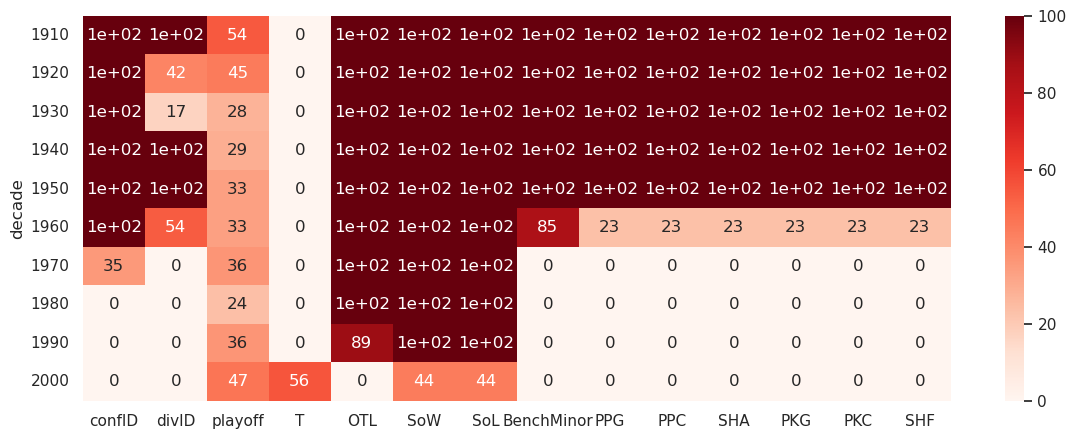

In [57]:
teams_nhl = q("""
    SELECT
        *
    FROM Teams
    WHERE lgID = "NHL"
""")


teams_nhl["decade"] = (teams_nhl["year"] // 10) * 10

teams_nhl_pct = (
    teams_nhl
        .drop(columns="decade")
        .isna()
        .groupby(teams_nhl["decade"])
        .mean() * 100
)

teams_nhl_pct = teams_nhl_pct.round(1)

teams_nhl_pct = teams_nhl_pct.loc[:, (teams_nhl_pct > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(teams_nhl_pct, annot=True, cmap="Reds")
plt.show()


**Result:** 14 of the 27 columns of `Teams` have missing values; the other 13 (games, wins, losses, goals, points, penalty minutes, rank…) are 100% complete in every decade.

| Column(s) | Missing until | Type | Explanation |
|---|---|---|---|
| `PPG`, `PPC`, `SHA`, `PKG`, `PKC`, `SHF` | 1962 (first season 1963) | not recorded | special-teams statistics only kept from 1963 |
| `BenchMinor` | 1968 (first season 1969) | not recorded | bench minor penalties only kept from 1969 |
| `confID` | 1973 | structural | conferences created in 1974 |
| `divID` | gaps until 1966 | structural | early seasons with a single group, no divisions |
| `OTL` | 1998 | structural | overtime-loss category created in 1999 |
| `T` | 2004 → NULL from 2005 | structural | ties abolished in 2005 |
| `SoW`, `SoL` | 2004 | structural | shootouts introduced in 2005 |
| `playoff` | every decade (24–55%) | meaningful | the team missed the playoffs |

**Only the special-teams columns are truly unknown**; every other missing value has a known meaning. **Action:** `T`, `OTL`, `SoW`, `SoL` → 0 where the event did not exist; `playoff` NULL → its own category ("missed the playoffs"); `confID`/`divID` are not used as features. Power-play and penalty-kill features are only available from **1963**.

#### 2.5.2 % missing per column per decade (NHL `Scoring` and `Goalies`)

The same measure for the player tables, which will be aggregated into team features (e.g. shots, save percentage).

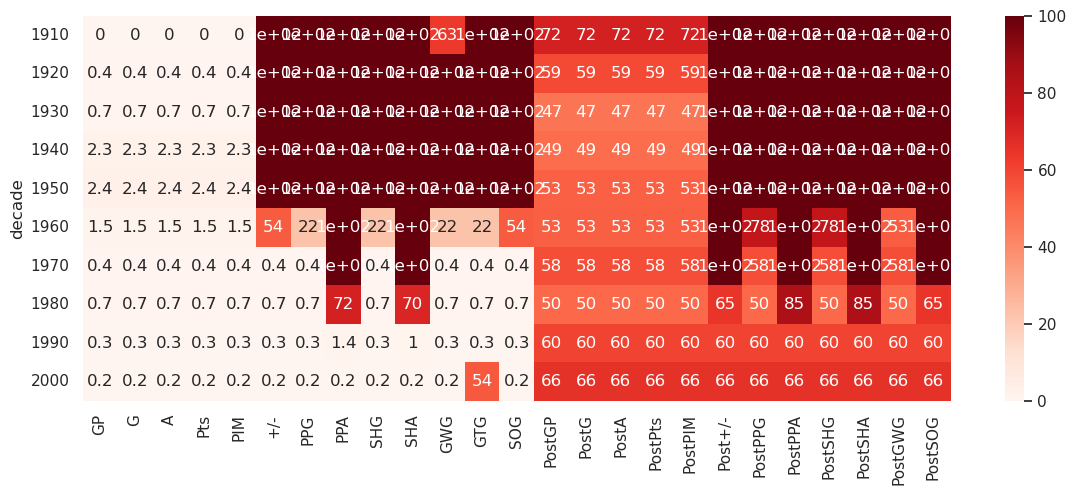

In [58]:
scoring_nhl = q("""
    SELECT
        *
    FROM Scoring
    WHERE lgID = "NHL"
""")


scoring_nhl["decade"] = (scoring_nhl["year"] // 10) * 10

scoring_nhl = (
    scoring_nhl
        .drop(columns="decade")
        .isna()
        .groupby(scoring_nhl["decade"])
        .mean() * 100
)

scoring_nhl = scoring_nhl.round(1)

scoring_nhl = scoring_nhl.loc[:, (scoring_nhl > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(scoring_nhl, annot=True, cmap="Reds")
plt.show()

**Result (`Scoring`):**
- **Basic statistics** (`GP`, `G`, `A`, `Pts`, `PIM`): under 2.5% missing in every decade. These 249 rows are players who **only played in the playoffs** for that team (247 of them have `PostGP`), so there is no regular-season line. Not a problem: summing per team ignores them.
- **Recorded from 1963:** `PPG`, `SHG`, `GWG`, `GTG`. **From 1967:** `SOG` (shots) and `+/-`. **From about 1987:** `PPA`, `SHA` (power-play and short-handed assists). All not recorded before.
- `GWG` is partly filled in the 1910s but then empty until 1963: an isolated early block, not usable.
- `GTG` (game-tying goals) is NULL in **every row from 2005**: structural, since a game can no longer end tied.
- `Post…` columns: 47–72% missing in every decade: meaningful, the player's team did not reach the playoffs (or the player did not play in them).

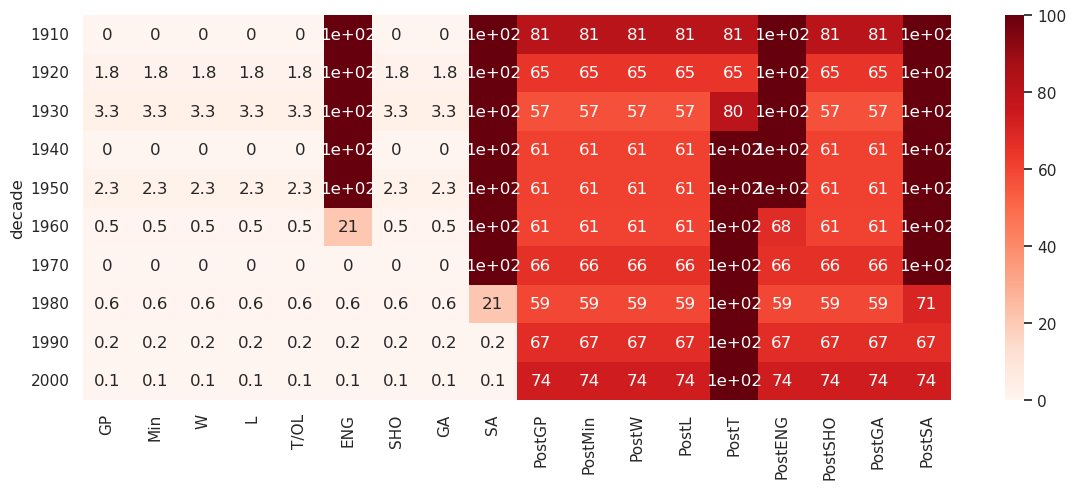

In [59]:
goalies_nhl = q("""
    SELECT
        *
    FROM Goalies
    WHERE lgID = "NHL"
""")


goalies_nhl["decade"] = (goalies_nhl["year"] // 10) * 10

goalies_nhl = (
    goalies_nhl
        .drop(columns="decade")
        .isna()
        .groupby(goalies_nhl["decade"])
        .mean() * 100
)

goalies_nhl = goalies_nhl.round(1)

goalies_nhl = goalies_nhl.loc[:, (goalies_nhl > 0).any()]
plt.figure(figsize=(14, 5))
sns.heatmap(goalies_nhl, annot=True, cmap="Reds")
plt.show()

**Result (`Goalies`):**
- **Basic statistics** (`GP`, `Min`, `W`, `L`, `GA`, `SHO`…): under 3.5% missing; the 18 rows are goalies who only played in the playoffs.
- `ENG` (empty-net goals) recorded from **1963**.
- **`SA` (shots against) recorded only from 1982** (21% missing in the 1980s, complete from 1990). Save percentage (1 − GA/SA), the usual measure of goalie quality, is therefore only possible from 1982.
- `PostT` is NULL in almost every row: there are no ties in the playoffs (overtime continues until a goal), so it is structural.

**Do the start years of team and player statistics line up?** Yes, in two steps: **1963** for special teams (`Teams.PPG`, `Scoring.PPG`, `Goalies.ENG`) and **1967** for shots and +/- (`Scoring.SOG`). Shots against for goalies come later, in **1982**.

#### 2.5.3 Coaches (the table built in Data Integration)

The % missing per decade in our coach table. The result is stored in a new variable so the coach table `df` is not overwritten.

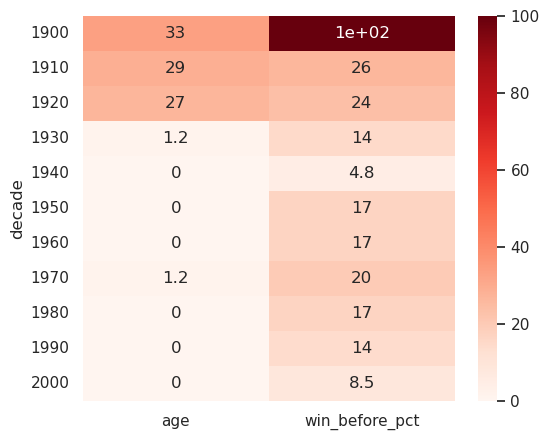

In [60]:
coach_missing = (
    df
        .isna()
        .groupby((df["year"] // 10) * 10)
        .mean() * 100
)

coach_missing = coach_missing.round(1)
coach_missing.index.name = "decade"

coach_missing = coach_missing.loc[:, (coach_missing > 0).any()]
plt.figure(figsize=(6, 5))
sns.heatmap(coach_missing, annot=True, cmap="Reds")
plt.show()

**Result:** only 2 of the 19 columns have missing values:
- **`win_before_pct`** (232 rows): **planned**. It is NaN for rookie coaches, who have no previous games, and `is_rookie_coach` already marks them. It is 100% in the 1900s because every coach was a rookie in the first season of the data.
- **`age`** (56 rows): the coach has no `birthYear` in `Master`. **52 of the 56 are before 1930** (early coaches with poorly documented lives), 1 is an NHL coach in the 1930s, and the other 3 are WHA coaches from the 1970s (Brian Shaw, Steve Neves). In the NHL from 1940 on, the age is always known. (Missing birth month or day was already handled in Data Integration: the age is computed on 1 August.)

**Action:** keep `win_before_pct` as NaN together with `is_rookie_coach` (decided in Missing values). The missing ages disappear with Era Selection if the cut is after 1940; otherwise they have to be imputed.

#### 2.5.4 Does every NHL team-season have a starting coach?

In [61]:
nhl_team_seasons = q("""
    SELECT year, franchID
    FROM Teams
    WHERE lgID = "NHL"
""")

coach_coverage = nhl_team_seasons.merge(
    df[["year", "franchID"]], on=["year", "franchID"], how="left", indicator=True
)

print(coach_coverage["_merge"].value_counts())

_merge
both          1265
left_only        0
right_only       0
Name: count, dtype: int64


**Result:** all **1,265** NHL team-seasons have exactly one row in the coach table (0 without a coach). **Action:** none; every row of the final table will have coach features.

#### 2.5.5 Does every team-season have goalies in `Goalies`?

In [62]:
goalies_each_season = q("""
    SELECT 
        goa.year,
        goa.tmID,
        goa.lgID
    FROM Goalies goa
    JOIN Teams t
        ON goa.year = t.year 
        AND goa.tmID = t.tmID 
        AND goa.lgID = t.lgID
    GROUP BY
        goa.year,
        goa.tmID,
        goa.lgID

""")

goalies_each_season.shape

(1459, 3)

**Result:** 1,459 team-seasons have at least one goalie, the same as the number of rows in `Teams` (all leagues). Together with the result in Accuracy (every team-season has players in `Scoring`), **the player tables cover every team**: aggregating them to team level does not create missing rows.

#### 2.5.6 Completeness summary

| Column(s) | Usable from | Type | Action |
|---|---|---|---|
| Team special teams (`PPG`, `PPC`, `PKG`, `PKC`, `SHA`, `SHF`) | 1963 | not recorded | only from 1963 |
| `Scoring.SOG` (shots), `+/-` | 1967 | not recorded | only from 1967 |
| `Goalies.SA` (save %) | 1982 | not recorded | only from 1982 |
| `T`, `OTL`, `SoW`, `SoL`, `GTG` | — | structural | count as 0 |
| `playoff`, `Post…` | — | meaningful | "missed the playoffs" category |
| `confID`, `divID` | — | structural | not used as features |
| Coach `win_before_pct` | — | planned (rookies) | keep NaN + `is_rookie_coach` |
| Coach `age` | complete in the NHL from 1940 | not recorded | solved by the era cut |
| Coverage (coach, players, goalies per team-season) | all seasons | — | none |

**Conclusion:** the basic statistics (games, wins, goals, points, penalties) are complete for the whole history, but the richer ones start in blocks. Completeness gives three **candidate start seasons** for Era Selection: **1963** (special teams), **1967** (shots and +/-; also the expansion from 6 to 12 teams) and **1982** (goalie shots against). The choice is a trade-off between more seasons and more features.

### 2.6 Timeliness

*Does the data cover the period we need, and is every value we use already known when the prediction is made?*

Timeliness has two sides in this project:
1. **Time coverage:** do all tables reach the last season, without holes?
2. **Availability at prediction time:** the predictions are made **the day before season t starts**, so every feature must be known at that moment. Using anything that only becomes known during or after season t is **leakage**.

#### 2.6.1 Time coverage of each table

In [63]:
teams_years = q("""
    SELECT
        year
    FROM Teams
    ORDER BY year
""")

different_years = teams_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [64]:
coaches_years = q("""
    SELECT
        year
    FROM Coaches
    ORDER BY year
""")

different_years = coaches_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [65]:
scoring_years = q("""
    SELECT
        year
    FROM Scoring
    ORDER BY year
""")

different_years = scoring_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [66]:
goalies_years = q("""
    SELECT
        year
    FROM Goalies
    ORDER BY year
""")

different_years = goalies_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1909. The last year is: 2009.
There is different 100 years


In [67]:
awards_coaches_years = q("""
    SELECT
        year
    FROM AwardsCoaches
    ORDER BY year
""")

different_years = awards_coaches_years["year"].unique()
first_year = different_years[0]
last_year = different_years[len(different_years) - 1]

print(f'The first year is: {first_year}. The last year is: {last_year}.')
print(f'There is different {len(different_years)} years')

The first year is: 1930. The last year is: 2009.
There is different 53 years


In [68]:
teams_seasons = teams_years["year"].unique()

all_seasons = set(range(teams_seasons.min(), teams_seasons.max() + 1))
missing_seasons = sorted(all_seasons - set(teams_seasons))

print(f"Seasons missing in Teams between {teams_seasons.min()} and {teams_seasons.max()}: {missing_seasons}")

Seasons missing in Teams between 1909 and 2009: [2004]


In [69]:
q("""
    SELECT award, lgID, MIN(year) AS first_year, MAX(year) AS last_year, COUNT(*) AS n_awards
    FROM AwardsCoaches
    GROUP BY award, lgID
    ORDER BY first_year
""")

,award,lgID,first_year,last_year,n_awards
0,First Team All-Star,NHL,1930,1945,16
1,Second Team All-Star,NHL,1930,1945,16
2,Baldwin,WHA,1972,1973,2
3,Jack Adams,NHL,1973,2009,36
4,Schmertz,WHA,1974,1978,5


In [70]:
q("""
    SELECT year, COUNT(*) AS n_teams, SUM(playoff IS NOT NULL) AS n_playoff_teams
    FROM Teams
    WHERE lgID = "NHL" AND year >= 2000
    GROUP BY year
""")

,year,n_teams,n_playoff_teams
0,2000,30,16
1,2001,30,16
2,2002,30,16
3,2003,30,16
4,2005,30,16
5,2006,30,16
6,2007,30,16
7,2008,30,16
8,2009,30,16


**Result:**

| Table | First season | Last season | Distinct seasons |
|---|---|---|---|
| `Teams` | 1909 | 2009 | 100 |
| `Coaches` | 1909 | 2009 | 100 |
| `Scoring` | 1909 | 2009 | 100 |
| `Goalies` | 1909 | 2009 | 100 |
| `AwardsCoaches` | 1930 | 2009 | 53 |

- The main tables all cover **1909–2009**. 1909 to 2009 is 101 seasons, and the missing one is **2004**: the season was cancelled by the **lockout**. It is a real hole in time, already handled in Data Integration (season numbers built from the distinct years, so 2003 → 2005 counts as consecutive).
- **The last season is complete:** 2009 has the same 30 NHL teams and 16 playoff teams as the seasons before it, so it is a full season and can be used as the most recent test season.
- **`AwardsCoaches` has a gap in time.** The NHL "All-Star" coach awards exist only from **1930 to 1945**, then **no coach award at all from 1946 to 1972**, and the Jack Adams Award only from **1973** (plus two WHA awards in the 1970s). So `awards_before` = 0 means "no award won" from 1973 on, but in the 1950s and 1960s it means "**no award existed**". The feature does not mean the same thing across eras: a structural zero. **Action:** take it into account in Era Selection; if older seasons are kept, `awards_before` is only comparable from about 1973 on.

#### 2.6.2 Is every feature known the day before season t?

Every column of the coach table, with what it is built from:

| Feature | Built from | Known before t? |
|---|---|---|
| `age` | birth date, measured at 1 August of season t | yes |
| `former_player` | the coach has a `playerID` in `Master` | yes, with a caveat (below) |
| `former_nhl_player` | the coach has a `firstNHL` in `Master` | **not always** (below) |
| `seasons_before`, `games_before`, `wins_before`, `losses_before`, `ties_before`, `postgames_before` | running totals of seasons **< t** (grouped shift) | yes (checked in Data Integration) |
| `win_before_pct` | the `_before` totals | yes |
| `is_rookie_coach` | `games_before` = 0 | yes |
| `awards_before` | awards of seasons **< t** (an award for season t is only given after the playoffs, so it counts from t+1) | yes (checked in Data Integration) |
| `tenure_before` | consecutive seasons with the franchise **before** t | yes (checked in Data Integration) |
| starting coach (`stint` = 1) | the coach who starts season t | yes, **assumption**: the starting coach is known before the first game |

**Caveat on the former-player flags.** They only check whether a playing career *exists* in `Master`, not whether it happened **before** season t. In **29** starting-coach seasons, the coach's first NHL season is season t itself or later: **player-coaches** in the early years (e.g. Newsy Lalonde and Art Ross in 1917), all **before 1928**. In those rows the flag uses information from the future. **Action:** the era cut removes them; if earlier seasons are kept, the flag must compare `firstNHL` with `year` (`firstNHL < year`).

**What must never be a feature:** anything from season t itself: the team's `W`, `GF`, `Pts`, `rank` or `playoff` of t, the coaches with stint > 1 in t, or the number of coaches of t (`n_stints`). These are exactly the targets (or contain them). **`n_stints` was dropped** for this reason. The same rule will hold for the team features: **team features for season t use only seasons ≤ t−1.**

#### 2.6.3 Is old data still representative?

Timeliness is also about whether old data still describes the game we predict. Many things changed over the 100 seasons:
- **games per season:** 22 (1917) → 48 (1994 lockout season) → 80–84 (modern NHL);
- **number of teams:** 4 (1917) → 6 (1942–1966) → 12 (1967) → 30 (2000s);
- **rules:** overtime losses counted from 1999; ties abolished and the shootout introduced in 2005;
- **recorded statistics:** special teams from 1963, shots and +/- from 1967, goalie shots against from 1982 (see Completeness);
- **coach awards:** none from 1946 to 1972;
- **coaches:** player-coaches in the early years.

**Conclusion:** the older the season, the less it resembles the seasons we predict. This is the reason for the next step, **Sampling for the domain**.

**Consequence for evaluation:** because the data is ordered in time, train and test must be **split by season**: train on earlier seasons, test on later ones (e.g. the last seasons up to 2009). A random split would let the model learn from seasons after the one it predicts.

### 2.7 Data Quality Summary

*Summary of the data quality assessment on the source tables; the details and the check cells are in each subsection above.*

| Dimension | Check | Rows failing | Explanation | Action |
|---|---|---|---|---|
| Uniqueness | (year, tmID) and (year, franchID) unique in `Teams` | 0 | — | none; (year, franchID) is the key of the final table |
| Uniqueness | same name + birth year in `Master` | 3 pairs | different people (different birth dates, careers) | join on IDs, never on names |
| Uniqueness | one stint-1 coach per team-season | 1 (DET 1998) | co-coaches Lewis and Smith | merged into one averaged row |
| Consistency | W + L + T + OTL = G; Pts = 2W + T + OTL (`Teams`) | 0 | NULL `T` (2005–2009) and `OTL` (before 1999) are structural | NULL → 0 |
| Consistency | g = w + l + t (`Coaches`) | 0 | — | none |
| Consistency | coach games = team games | 1 (DET 1998) | the same 5 games recorded once per co-coach (77 + 5 + 5 = 87) | none (handled by the merged row) |
| Consistency | meaning of `G` | — | goals in `Scoring`, games in `Teams`/`Coaches` | rates use `Teams.G` and `Scoring.GP` |
| Accuracy | `Teams.GF` = sum of player goals | 160 of 1,459 | 11 ±1 recording errors (1916–1934); 149 = shootout wins from 2005 (shootout goal not credited to a player) | keep `GF`/`GA` from `Teams` |
| Accuracy | awards vs coached seasons | 1 | Tippett's 2009 award with no 2009 season in `Coaches` | none (no season after 2009) |
| Validity | negative counts; W > G, PPG > PPC, PKG > PKC; rank > teams in group | 0 | — | none; rank is within the division |
| Validity | same games for all teams of an NHL season | 1 season (1917) | Montreal Wanderers withdrew after their arena burned | accepted (real event); per-game rates |
| Validity | player GP ≤ team G | 6 (1921 WCHL) | extra game recorded on one side only | outside scope (not NHL) |
| Validity | playoff codes in `abbrev.csv` | 0 unknown | `ND` = 1919 final halted by flu; `NHLF` = lost NHL final | map to an ordinal in feature engineering |
| Validity | dates, height, weight in `Master` | 0 | 1841/1858 births are Hall of Fame builders | none |
| Completeness | special teams (`PPG`, `PPC`, `PKG`, `PKC`, `SHA`, `SHF`) | 100% before 1963 | not recorded | only usable from 1963 |
| Completeness | shots and +/- (`Scoring`) | 100% before 1967 | not recorded | only usable from 1967 |
| Completeness | goalie shots against (`Goalies.SA`) | 100% before 1982 | not recorded | save % only from 1982 |
| Completeness | `T`, `OTL`, `SoW`, `SoL`, `GTG` | by era | structural (event did not exist) | NULL → 0 |
| Completeness | `playoff`, `Post…` | 24–55% / 47–72% | meaningful (missed the playoffs) | separate category |
| Completeness | coach `win_before_pct` | 232 | planned (rookie coaches) | keep NaN + `is_rookie_coach` |
| Completeness | coach `age` | 56 | no birth year; 52 before 1930, none in the NHL from 1940 | solved by era cut |
| Completeness | coach, players and goalies for every team-season | 0 missing | — | none |
| Timeliness | missing seasons 1909–2009 | 1 (2004) | lockout | season numbers built from distinct years |
| Timeliness | coach awards over time | 1946–1972 | no coach award existed | `awards_before` only comparable from 1973 |
| Timeliness | features known before season t | 29 | former-player flags for player-coaches before 1928 | solved by era cut, or compare `firstNHL < year` |

#### 2.7.1 Decisions carried forward

1. **Missing values:** `T`, `OTL`, `SoW`, `SoL` NULL → 0; `playoff` NULL → "missed the playoffs"; `win_before_pct` stays NaN together with `is_rookie_coach`; missing coach ages only if the era cut keeps seasons before 1940.
2. **Era Selection:** the candidate start seasons are **1963** (special teams), **1967** (shots, +/-, expansion to 12 teams), **1973** (coach awards comparable) and **1982** (goalie save %). Any cut from 1963 on also removes the missing coach ages and the leaky former-player flags.
3. **Feature engineering:** convert counts to **per-game rates**; combine `T` and `OTL` into one "non-win, non-loss" column; map the playoff codes (including `ND` and `NHLF`) to one ordinal scale across eras; take `GF`/`GA` from `Teams`; remember that `rank` is within the division.
4. **Team-side integration:** join on IDs (`franchID`, `tmID`, `playerID`, `coachID`), never on names; team features for season t use only seasons ≤ t−1.
5. **Evaluation:** split train and test by season (earlier seasons for training, later for testing), never randomly.

**Conclusion:** the source data is almost free of errors. Every unusual value we found is a real historical event (the 1917 Wanderers, the 1919 flu final, the 2004 lockout) or a difference in definitions (shootout goals, the two meanings of `G`), and only 11 one-goal errors remain in seasons we will not use. The main limitation is **incompleteness over time**: the richer statistics, and even some rules, only exist from certain seasons. That makes choosing the starting season the next decision (section 3).

## 3. Sampling for the domain: which seasons to use?

Not every team-season in the database is relevant to the problem: the predictions are about the NHL as it is played today, and Data Quality showed that the oldest seasons are incomplete and played under different rules. This section selects the rows (team-seasons) of the final dataset, in two filters: **league** and **start season**.

### 3.1 League choice

In [71]:
sampling_domain_teams = q("""
    SELECT
        lgID, year
    FROM Teams
""")



sampling_domain_teams_count = (
    sampling_domain_teams
    .groupby("lgID")["year"]
    .agg(rows="count", first_season="min", last_season="max")
    .sort_values("rows", ascending=False)
)
print(sampling_domain_teams_count)

      rows  first_season  last_season
lgID                                 
NHL   1265          1917         2009
WHA     84          1972         1978
NHA     45          1909         1916
PCHA    41          1911         1923
WCHL    24          1921         1925


**Result:** the NHL has 1,265 of the 1,459 team-seasons and is the only league that covers the whole period up to 2009. The other four leagues ended between 1916 and 1978 (the WHA merged four of its teams into the NHL in 1979) and had different schedules and rules.

**Decision:** keep **only NHL team-seasons as rows**. The other leagues are removed as rows, **not as history**: a coach's experience in the WHA or another league still counts in the career features (`seasons_before`, `games_before`…), because coach history was built on all leagues in Data Integration.

### 3.2 Start season

Completeness and Timeliness gave four candidate start seasons, each one adding information: **1963** (special-teams statistics), **1967** (shots and +/-; expansion from 6 to 12 teams), **1973** (coach awards comparable: Jack Adams Award) and **1982** (goalie shots against, so save %). The candidates are marked with dashed lines.

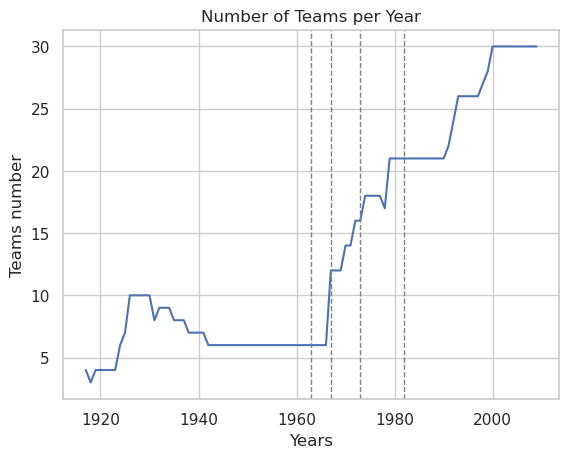

In [72]:
sampling_domain_year = q("""
    SELECT
        year,
        tmID,
        lgID
    FROM Teams
    WHERE lgID = "NHL"
""")

sampling_domain_year_groupby = sampling_domain_year.groupby("year")["lgID"].agg(teams_season="count").sort_values("year", ascending=False)

sampling_domain_year_groupby.head()

plt.plot(sampling_domain_year_groupby.index, sampling_domain_year_groupby["teams_season"])
plt.xlabel("Years")
plt.ylabel("Teams number")
plt.title("Number of Teams per Year")
possible_candidates = [1963, 1967, 1973, 1982]
for x in possible_candidates:
    plt.axvline(x, ls="--", color="grey", lw=1)


**Number of teams:** between 3 and 10 teams until 1941, the six teams of the "Original Six" era from 1942 to 1966, then fast growth: 12 teams in 1967, 21 in 1979 (WHA merger), 30 from 2000. From **1979 to 1990 the league is stable at 21 teams**, and from 1982 every season has the same structure: 2 conferences, 16 playoff teams and divisions (4 until 1997, 6 from 1998).

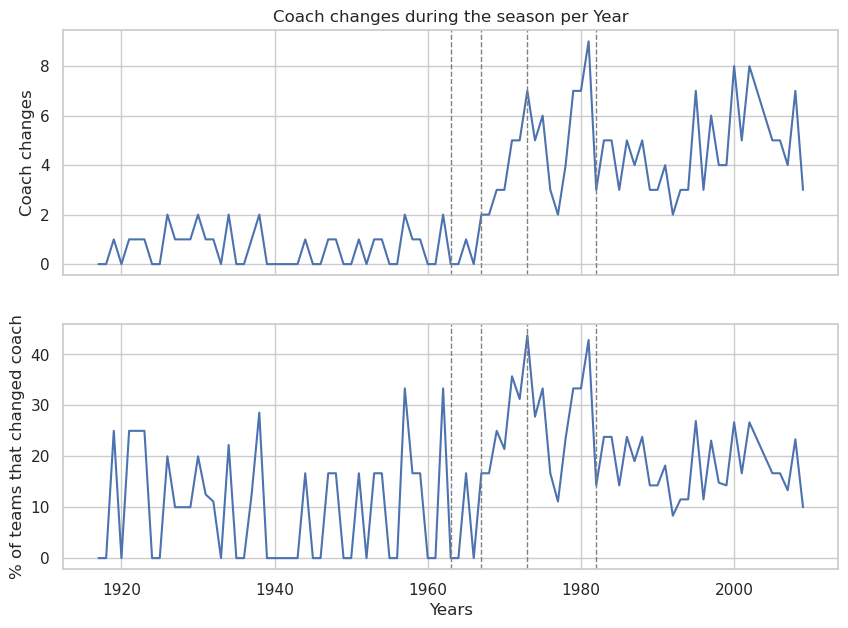

In [73]:
sampling_domain_changes = q("""
    SELECT
        c.year,
        c.tmID,
        MAX(c.stint) > 1 AS coach_change
    FROM Coaches c
    WHERE c.lgID = "NHL"
    GROUP BY
        c.year,
        c.tmID
""")

sampling_domain_changes_groupby = (
    sampling_domain_changes
    .groupby("year")["coach_change"]
    .agg(changes="sum", teams_season="count")
)

sampling_domain_changes_groupby["changes_pct"] = (
    sampling_domain_changes_groupby["changes"] / sampling_domain_changes_groupby["teams_season"] * 100
)

fig, (ax_count, ax_pct) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax_count.plot(sampling_domain_changes_groupby.index, sampling_domain_changes_groupby["changes"])
ax_count.set_ylabel("Coach changes")
ax_count.set_title("Coach changes during the season per Year")

ax_pct.plot(sampling_domain_changes_groupby.index, sampling_domain_changes_groupby["changes_pct"])
ax_pct.set_xlabel("Years")
ax_pct.set_ylabel("% of teams that changed coach")

for ax in (ax_count, ax_pct):
    for x in possible_candidates:
        ax.axvline(x, ls="--", color="grey", lw=1)

plt.show()

**Coach changes during the season:** the count (top) grows with the number of teams, so the % (bottom) is the fair comparison. Before the 1960s changes are rare (often 0–2 per season, about 11% of teams per decade); the **1970s** are the peak (about 28% of teams per decade, 7 of 21 teams in 1979); from the 1980s the rate settles between about 15% and 23% per decade. Task (b) is a **minority class** in every era (about 1 team in 5).

### 3.3 Choose and justify

The candidates compared: rows kept, task (b) positives kept, and what each cut adds.

In [74]:
candidates = []

for start in possible_candidates:
    kept = sampling_domain_changes_groupby[sampling_domain_changes_groupby.index >= start]
    candidates.append({
        "start_season": start,
        "team_seasons": kept["teams_season"].sum(),
        "coach_changes": kept["changes"].sum(),
        "changes_pct": round(kept["changes"].sum() / kept["teams_season"].sum() * 100, 1),
    })

candidates = pd.DataFrame(candidates)
candidates

,start_season,team_seasons,coach_changes,changes_pct
0,1963,962,195,20.3
1,1967,938,194,20.7
2,1973,858,174,20.3
3,1982,690,124,18.0


| Start | Team-seasons | Coach changes | % | Adds |
|---|---|---|---|---|
| 1963 | 962 | 195 | 20.3 | special teams |
| 1967 | 938 | 194 | 20.7 | shots, +/-; 12-team league |
| 1973 | 858 | 174 | 20.3 | comparable coach awards |
| 1982 | 690 | 124 | 18.0 | goalie save %; stable modern structure |

**Decision: NHL team-seasons from 1982 to 2009** (690 rows).

**Why 1982:**
- **Every feature is available.** It is the first season with goalie shots against, so save % (the main measure of goalie quality) can be used; special teams, shots, +/- and the Jack Adams Award are all recorded too. No feature has to be dropped or flagged as "not recorded".
- **The league structure is stable and modern.** From 1982 every season has 2 conferences, 16 playoff teams, divisions, and 80–84 games (except the 48-game 1994 season). The team count only grows by expansion (21 → 30), with no merger.
- **The targets are comparable across all seasons.** Task (a) ranks teams within their division, and divisions exist in every season. The playoff result always has **four rounds** (DSF → DF → CF → F until 1992, CQF → CSF → CF → F from 1993), so it maps to the same ordinal scale in every season.
- **It is closest to the seasons we predict**, which matters because the game changed a lot over time (see Timeliness).

**The cost:** 1982 keeps 248 fewer rows than 1967 and **70 fewer coach changes** (124 instead of 194, −36%), the minority class of task (b). We accept it because the earlier seasons would bring incomplete features and a different league structure; the low number of positives is handled in the imbalance step.

**Solved automatically by the cut** (from the Data Quality decisions):
- the 29 leaky former-player flags (all before 1928) and the missing coach ages (none in the NHL from 1940);
- every "not recorded" block of `Teams`, `Scoring` and `Goalies` (special teams, shots, save %);
- the coach-award gap (1946–1972): `awards_before` means the same in every row;
- the 11 one-goal errors in `GF` (1916–1934) and the old-league anomalies (1917 Wanderers, 1921 WCHL).

### 3.4 History before the cut

The cut selects the **rows** (the seasons we predict), not the **data** used to build their features. Features of season t use season t−1 (and the coach's whole career), so the seasons before 1982 stay in the database as history:
- the 1982 rows use the 1981 team statistics;
- coach career features (`seasons_before`, `games_before`, `awards_before`, `tenure_before`…) use every season since 1909, in every league.

Three special cases follow from this.

In [75]:
nhl_franchises = q("""
    SELECT year, franchID, tmID, name
    FROM Teams
    WHERE lgID = "NHL"
""")

first_season = nhl_franchises.groupby("franchID")["year"].transform("min") == nhl_franchises["year"]

nhl_franchises[first_season & (nhl_franchises["year"] >= 1982)]

,year,franchID,tmID,name
780,1991,SJS,SJS,San Jose Sharks
799,1992,OTT,OTT,Ottawa Senators
805,1992,TBL,TBL,Tampa Bay Lightning
810,1993,ANA,ANA,Mighty Ducks of Anaheim
818,1993,FLO,FLO,Florida Panthers
953,1998,NAS,NAS,Nashville Predators
968,1999,WPG,ATL,Atlanta Thrashers
1001,2000,CBS,CBS,Columbus Blue Jackets
1009,2000,MIN,MIN,Minnesota Wild


In [76]:
q("""
    SELECT year, COUNT(*) AS goalie_rows, SUM(SA IS NULL) AS sa_missing
    FROM Goalies
    WHERE lgID = "NHL" AND GP IS NOT NULL AND year BETWEEN 1980 AND 1984
    GROUP BY year
""")

,year,goalie_rows,sa_missing
0,1980,78,78
1,1981,72,72
2,1982,74,0
3,1983,72,0
4,1984,69,0


**1. Expansion teams have no previous season.** 9 franchises play their first NHL season after the cut: San Jose (1991), Ottawa and Tampa Bay (1992), Anaheim and Florida (1993), Nashville (1998), Atlanta (1999, `franchID` WPG, because the franchise later moved to Winnipeg), Columbus and Minnesota (2000). Their t−1 team features are NaN (handled in Missing values); their coach features exist normally.

**2. Save % of the previous season starts one year later.** Goalie shots against are recorded from 1982 but **missing in every 1981 row**. So the 1982 rows have no t−1 save %: it is available as a feature from the **1983** rows. **Action:** decide in Missing values between imputing the 21 values of 1982 or starting save % features one season later.

**3. Two previous seasons are special.**
- The t−1 of **2005** is **2003**, because 2004 was cancelled (lockout). The season numbers from Data Integration already handle this.
- The t−1 of **1995** is the **48-game 1994 season**. Per-game rates make it comparable with the 80–84-game seasons.

### 3.5 Apply and check

The two filters are applied to the coach table `df`: NHL only, seasons 1982 to 2009.

#### 3.5.1 Apply

In [77]:
df = df[(df["year"] >= 1982) & (df["lgID"] == "NHL")]

df.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,games_before,wins_before,ties_before,losses_before,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before
769,cheevge01c,1982,NHL,BOS,BOS,1,41.0,1,1,2.0,160.0,80.0,23.0,57.0,14.0,0.571875,0,0.0,2
767,bowmasc01c,1982,NHL,BUF,BUF,1,48.0,0,0,14.0,987.0,594.0,173.0,220.0,168.0,0.689463,0,1.0,1
771,johnsbo02c,1982,NHL,CAL,CAL,1,51.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
773,kishla01c,1982,NHL,CAR,HAR,1,40.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0
783,tessior01c,1982,NHL,CHI,CHI,1,49.0,1,1,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,0.0,0


**Result:** `df` goes from **1,454** rows (every league, 1909–2009) to **690** rows (NHL, 1982–2009).

#### 3.5.2 Checks

In [78]:
nhl_since_1982 = q("""
    SELECT year, franchID
    FROM Teams
    WHERE lgID = "NHL" AND year >= 1982
""")

print(f"Rows in df: {len(df)}. NHL team-seasons in Teams since 1982: {len(nhl_since_1982)}")
print(f"Duplicate (year, franchID): {df.duplicated(subset=['year', 'franchID']).sum()}")
print(f"Seasons: {df['year'].min()} to {df['year'].max()}, {df['year'].nunique()} distinct")
print(f"Leagues: {list(df['lgID'].unique())}")
print(f"Missing age: {df['age'].isna().sum()}")

Rows in df: 690. NHL team-seasons in Teams since 1982: 690
Duplicate (year, franchID): 0
Seasons: 1982 to 2009, 27 distinct
Leagues: ['NHL']
Missing age: 0


**Result:**
- `df` has **690 rows**, the same as the NHL team-seasons in `Teams` since 1982: **one row per franchise-season, none missing**.
- 0 duplicate (year, franchID); seasons 1982 to 2009, **27 distinct** (2004 missing because of the lockout); only the NHL.
- 0 missing ages: the era cut solved them, as expected from Completeness.

**Action:** none. `df` is the base table for section 4, where the targets and the team features are added.

## 4. Build the dataset (feature engineering)

This section **constructs** the attributes that do not exist in any table: the two targets (season t) and the team features (seasons ≤ t−1). It also **completes the integration** started in section 1, by joining the team side to the coach table. The result is one table, `dataset`, with one row per NHL franchise-season from 1982 (690 rows) and key (year, franchID).

Every column has one of three roles:
- **`target_`**: what the model predicts (season t);
- **`eval_`**: season t, only used to evaluate the predictions (never given to the model);
- **features** (no prefix): only information from seasons before t.

### 4.1 Targets


#### 4.1.1 Target (a): points percentage of season t

Task (a) predicts the final regular-season ranking. As defined in Business Understanding, we predict each team's **points percentage** `Pts / (2·G)` (the share of the maximum possible points) and then sort the teams. Predicting `rank` directly would be harder to learn: it depends on the size of the division (4 to 7 teams per division-season from 1982) and on the other teams in it. `divID`, `confID`, `rank` and `playoff` of season t are kept as evaluation columns, to compare the predicted ranking with the real one.

In [79]:
targets_a = q("""
    SELECT
        t.year,
        t.franchID,
        t.Pts * 1.0 / (2 * t.G) AS target_pts_pct,
        t.divID AS eval_divID,
        t.confID AS eval_confID,
        t.rank AS eval_rank,
        t.playoff AS eval_playoff
    FROM Teams t
    WHERE t.year >= 1982 AND t.lgID = "NHL"
""")

dataset = pd.merge(df, targets_a, on=["year", "franchID"], how="left", validate="one_to_one")

dataset.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,...,postgames_before,win_before_pct,is_rookie_coach,awards_before,tenure_before,target_pts_pct,eval_divID,eval_confID,eval_rank,eval_playoff
0,cheevge01c,1982,NHL,BOS,BOS,1,41.0,1,1,2.0,...,14.0,0.571875,0,0.0,2,0.68750,AD,WA,1,CF
1,bowmasc01c,1982,NHL,BUF,BUF,1,48.0,0,0,14.0,...,168.0,0.689463,0,1.0,1,0.55625,AD,WA,3,DF
2,johnsbo02c,1982,NHL,CAL,CAL,1,51.0,0,0,0.0,...,0.0,NaN,1,0.0,0,0.48750,SM,CC,2,DF
3,kishla01c,1982,NHL,CAR,HAR,1,40.0,0,0,0.0,...,0.0,NaN,1,0.0,0,0.28125,AD,WA,5,None
4,tessior01c,1982,NHL,CHI,CHI,1,49.0,1,1,0.0,...,0.0,NaN,1,0.0,0,0.65000,NO,CC,1,CF


#### 4.1.2 Points percentage relative to the season average

The average points % of a season is not constant across eras:

In [80]:
season_mean = dataset.groupby("year")["target_pts_pct"].mean().round(3)

print(season_mean.loc[[1982, 1998, 1999, 2003, 2005, 2009]])

year
1982    0.500
1998    0.500
1999    0.525
2003    0.529
2005    0.557
2009    0.561
Name: target_pts_pct, dtype: float64


It is exactly **0.500 until 1998**: every game gives 2 points in total (2 to the winner, or 1 + 1 for a tie). From **1999** a team that loses in overtime gets 1 point (OTL), so an overtime game gives 3 points in total and the average rises to about **0.525–0.53**. From **2005** every tied game goes to overtime or a shootout and gives 3 points, so it rises to about **0.56**.

So the same points % means different things in different eras: 0.55 is average in 2007 but good in 1990. We add a second version of the target, **relative to the season average**:

> `target_pts_pct_rel` = team's points % − mean points % of all teams in the same season

0 means an average team in that season; positive is better than average, negative worse.

In [81]:
dataset["target_pts_pct_rel"] = (
    dataset["target_pts_pct"]
    - dataset.groupby("year")["target_pts_pct"].transform("mean")
)

dataset[["year", "franchID", "target_pts_pct", "target_pts_pct_rel"]].head()

,year,franchID,target_pts_pct,target_pts_pct_rel
0,1982,BOS,0.68750,0.18750
1,1982,BUF,0.55625,0.05625
2,1982,CAL,0.48750,-0.01250
3,1982,CAR,0.28125,-0.21875
4,1982,CHI,0.65000,0.15000


#### 4.1.3 Checks on target (a)

In [82]:
print(f"Rows: {len(dataset)}")
print(f"Duplicate (year, franchID): {dataset.duplicated(subset=['year', 'franchID']).sum()}")
print(f"Missing target_pts_pct: {dataset['target_pts_pct'].isna().sum()}")
print(f"target_pts_pct from {dataset['target_pts_pct'].min():.3f} to {dataset['target_pts_pct'].max():.3f}, mean {dataset['target_pts_pct'].mean():.3f}")

rel_season_mean = dataset.groupby("year")["target_pts_pct_rel"].mean().abs().max()
print(f"Largest |season mean| of target_pts_pct_rel: {rel_season_mean:.1e}")

same_order = (
    dataset.groupby("year")["target_pts_pct"].rank()
    == dataset.groupby("year")["target_pts_pct_rel"].rank()
).all()
print(f"Same ranking within each season with both targets: {same_order}")

Rows: 690
Duplicate (year, franchID): 0
Missing target_pts_pct: 0
target_pts_pct from 0.143 to 0.799, mean 0.518
Largest |season mean| of target_pts_pct_rel: 7.0e-17
Same ranking within each season with both targets: True


**Result:**
- 690 rows, 0 duplicate keys and **0 missing targets**: every franchise-season of `df` found its row in `Teams` (the join is one to one).
- `target_pts_pct` goes from **0.143** (Ottawa and San Jose 1992, both in their first season) to **0.799** (Detroit 1995), mean 0.518.
- The relative target has mean 0 in every season (up to rounding errors of about 1e-16), and it gives **the same ranking** as the raw target in every season: the same value is subtracted from every team of a season, so the order does not change.

**Decision:** keep both columns. The ranking of task (a) is the same with either, so the choice only matters for the regression: `target_pts_pct_rel` removes the change between eras, so the model does not have to learn it; `target_pts_pct` is easier to interpret. The modelling step compares the two.

**Note on timing:** the exact season mean of t is not known before season t (it depends on how many games go to overtime). This is not a problem, because the predictions are only used to rank the teams inside the same season, so they never have to be converted back to raw points.

**Consequence for 4.2:** the points % of t−1 has the same drift (e.g. the 2005 rows use 2003, a season with a mean of 0.529), so it is also built relative to the mean of its own season.

#### 4.1.4 Target (b): coach change during season t

As decided in Business Understanding, task (b) predicts whether a team **changes coach during season t** (a coach is replaced mid-season). The coach features of each row describe the coach who **started** season t (stint 1), who is known the day before the season.

A team changed coach during the season if any of its coaches in that season has `stint > 1` (a second or third coach came in). `Coaches` has no `franchID`, so it is joined with `Teams` on the same three keys as in section 1 (year, tmID, lgID).

In [83]:
targets_b = q("""
    SELECT
        c.year,
        t.franchID,
        MAX(c.stint) AS max_stint,
        COUNT(*) AS n_coach_rows,
        MAX(c.stint) > 1 AS target_coach_changes_during
    FROM Coaches c
    INNER JOIN Teams t
        ON t.year = c.year
        AND t.tmID = c.tmID
        AND t.lgID = c.lgID
    WHERE c.year >= 1982 AND c.lgID = "NHL"
    GROUP BY c.year, t.franchID
""")

dataset = pd.merge(
    dataset,
    targets_b[["year", "franchID", "target_coach_changes_during"]],
    on=["year", "franchID"],
    how="left",
    validate="one_to_one",
)

dataset.head()

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,...,is_rookie_coach,awards_before,tenure_before,target_pts_pct,eval_divID,eval_confID,eval_rank,eval_playoff,target_pts_pct_rel,target_coach_changes_during
0,cheevge01c,1982,NHL,BOS,BOS,1,41.0,1,1,2.0,...,0,0.0,2,0.68750,AD,WA,1,CF,0.18750,0
1,bowmasc01c,1982,NHL,BUF,BUF,1,48.0,0,0,14.0,...,0,1.0,1,0.55625,AD,WA,3,DF,0.05625,0
2,johnsbo02c,1982,NHL,CAL,CAL,1,51.0,0,0,0.0,...,1,0.0,0,0.48750,SM,CC,2,DF,-0.01250,0
3,kishla01c,1982,NHL,CAR,HAR,1,40.0,0,0,0.0,...,1,0.0,0,0.28125,AD,WA,5,None,-0.21875,1
4,tessior01c,1982,NHL,CHI,CHI,1,49.0,1,1,0.0,...,1,0.0,0,0.65000,NO,CC,1,CF,0.15000,0


Two possible rules for "the team changed coach": **max(stint) > 1** (used here) or **more than one coach row** (used in `sql/coach_changes.sql`). They only disagree for co-coaches with no replacement (two stint-1 rows and no stint 2). Do they disagree in any row from 1982, and how many changes happen in one season?

In [84]:
rule_rows = (targets_b["n_coach_rows"] > 1).astype(int)
disagree = targets_b[rule_rows != targets_b["target_coach_changes_during"]]
print(f"Rows where the two rules disagree: {len(disagree)}")

print(targets_b["max_stint"].value_counts().sort_index())

print(targets_b[(targets_b["year"] == 1998) & (targets_b["franchID"] == "DET")])

Rows where the two rules disagree: 0
max_stint
1    566
2    107
3     17
Name: count, dtype: int64
     year franchID  max_stint  n_coach_rows  target_coach_changes_during
373  1998      DET          2             3                            1


**Result:** the two rules agree in **every row** (0 disagreements). Detroit 1998 has 3 coach rows and is a change under both rules: the co-coaches Lewis and Smith (both stint 1) were replaced by Bowman (stint 2). We keep **max(stint) > 1**, because it is the most direct meaning of "a new coach came in".

`max_stint`: **566** team-seasons with only the starting coach, **107** with one change and **17** with two changes in the same season (stint 3). The target is binary (changed or not), so a season with two changes counts as one positive.

#### 4.1.5 Checks on target (b)

In [85]:
print(f"Rows: {len(dataset)}")
print(f"Duplicate (year, franchID): {dataset.duplicated(subset=['year', 'franchID']).sum()}")
print(f"Missing target_coach_changes_during: {dataset['target_coach_changes_during'].isna().sum()}")
print(f"dtype: {dataset['target_coach_changes_during'].dtype}")

print(dataset["target_coach_changes_during"].value_counts())
print(f"Positives: {dataset['target_coach_changes_during'].mean() * 100:.1f}%")

print(dataset.groupby("target_coach_changes_during")["target_pts_pct"].mean().round(3))

Rows: 690
Duplicate (year, franchID): 0
Missing target_coach_changes_during: 0
dtype: int64
target_coach_changes_during
0    566
1    124
Name: count, dtype: int64
Positives: 18.0%
target_coach_changes_during
0    0.532
1    0.457
Name: target_pts_pct, dtype: float64


**Result:**
- 690 rows, 0 duplicate keys, **0 missing values**, integer 0/1: every team-season found its coaches.
- **124 positives and 566 negatives (18.0%)**, the same numbers as in section 3, which confirms the join and the filters.
- **Cross-check between the two targets:** teams that changed coach had a mean points % of **0.457**, against **0.532** for the others. This is expected (coaches are replaced when the team is losing) and confirms that both targets are on the right rows.

**Imbalance:** about **1 positive in 5.5**, a moderate imbalance. Accuracy would be misleading (always predicting "no change" is 82% accurate), so task (b) is evaluated with PR-AUC and the F1 of the positive class, and the imbalance is handled in its own section.

**What this tells us for 4.2:** the team's performance is strongly related to a coach change, so the team's **recent** performance (season t−1 and the trend before it) is likely the most important input for task (b). **Leakage warning:** `target_pts_pct` is the performance *during* season t, so it is related to the change but is a target column, never a feature for task (b).

### 4.2 Team features from season t−1

The targets showed that a team's performance is strongly related to both tasks. Here we describe **how each team played in the previous season**, in four steps: build the statistics of every team-season (4.2.1), map the playoff result to an ordinal (4.2.2), compute the goalie save % (4.2.3), then **lag** everything to season t−1 and join it to `dataset` (4.2.4–4.2.5).

#### 4.2.1 Per-season team statistics

One row per NHL team-season **s**, not lagged yet (the lag to t−1 is done in 4.2.4). The query is based on `sql/team_features.sql`, with two changes:
- **The first season is 1980**, not 1967: the 1982 rows need season **1981** as t−1, and a trend (t−1 compared with t−2) needs **1980**. Older seasons are never used.
- It also returns `rank`, `divID` and `playoff`, needed for the division rank (below) and the playoff ordinal (4.2.2), and the Pythagorean expectation.

All counts are divided by the games played (`G`), so seasons of different length (80, 84, 48, 82 games) are comparable. `NULLIF(…, 0)` avoids a division by zero if a team had no power-play chances.

In [86]:
team_season = q("""
    SELECT
        year, franchID, tmID, name, G,
        divID, rank, playoff,
        Pts * 1.0 / (2 * G)                          AS pts_pct,
        GF * 1.0 / G                                 AS gf_pg,
        GA * 1.0 / G                                 AS ga_pg,
        (GF - GA) * 1.0 / G                          AS gd_pg,
        PIM * 1.0 / G                                AS pim_pg,
        PPG * 1.0 / NULLIF(PPC, 0)                   AS pp_pct,      -- power-play conversion
        1 - PKG * 1.0 / NULLIF(PKC, 0)               AS pk_pct,      -- penalty-kill success
        PPC * 1.0 / G                                AS pp_opp_pg,   -- power-play chances drawn
        SHF * 1.0 / G                                AS shf_pg,      -- short-handed goals for
        GF * GF * 1.0 / (GF * GF + GA * GA)          AS pyth_pct,    -- Pythagorean expectation
        CASE WHEN playoff IS NULL THEN 0 ELSE 1 END  AS made_playoffs
    FROM Teams
    WHERE lgID = 'NHL' AND year >= 1980
    ORDER BY year, franchID
""")

team_season.head()

,year,franchID,tmID,name,G,divID,rank,playoff,pts_pct,gf_pg,ga_pg,gd_pg,pim_pg,pp_pct,pk_pct,pp_opp_pg,shf_pg,pyth_pct,made_playoffs
0,1980,BOS,BOS,Boston Bruins,80,AD,2,PRE,0.54375,3.9500,3.4000,0.5500,22.950,0.254386,0.770950,4.2750,0.1625,0.574413,1
1,1980,BUF,BUF,Buffalo Sabres,80,AD,1,QF,0.61875,4.0875,3.1250,0.9625,14.925,0.235484,0.835821,3.8750,0.1125,0.631114,1
2,1980,CAL,CAL,Calgary Flames,80,PT,3,SF,0.57500,4.1125,3.7250,0.3875,18.125,0.269103,0.807692,3.7625,0.1000,0.549321,1
3,1980,CAR,HAR,Hartford Whalers,80,NO,4,None,0.37500,3.6500,4.6500,-1.0000,19.800,0.188679,0.756098,3.9750,0.1625,0.381242,0
4,1980,CHI,CHI,Chicago Black Hawks,80,SM,2,PRE,0.48750,3.8000,3.9375,-0.1375,20.750,0.221854,0.750000,3.7750,0.1000,0.482235,1


Three features are derived in pandas, because they compare a team with the **other teams of the same season**:
- **`pts_pct_rel`**: points % minus the mean points % of the season (the decision of 4.1.2). It is computed **here, before the lag**, so each value is relative to the mean of its own season (e.g. 2003 relative to 2003, not to 2005).
- **`luck`**: points % minus the Pythagorean %, **both relative to their season mean**. Positive means the team won more points than its goals for and against justify (close wins, overtime results); such teams tend to come back down the following season. The Pythagorean % always averages about 0.5, while points % averages up to 0.56 from 2005 (4.1.2), so the raw difference would mostly measure the era; comparing both with their season mean removes that.
- **`rank_div_norm`**: the division rank on a 0–1 scale, `(rank − 1) / (teams in the division − 1)`. 0 is first and 1 is last, whatever the size of the division (4 to 7 teams), so "3rd of 4" and "3rd of 7" are no longer the same value.

In [87]:
team_season["pts_pct_rel"] = (
    team_season["pts_pct"]
    - team_season.groupby("year")["pts_pct"].transform("mean")
)

team_season["pyth_pct_rel"] = (
    team_season["pyth_pct"]
    - team_season.groupby("year")["pyth_pct"].transform("mean")
)

team_season["luck"] = team_season["pts_pct_rel"] - team_season["pyth_pct_rel"]

team_season["teams_in_div"] = team_season.groupby(["year", "divID"])["franchID"].transform("count")
team_season["rank_div_norm"] = (team_season["rank"] - 1) / (team_season["teams_in_div"] - 1)

team_season[["year", "franchID", "pts_pct", "pts_pct_rel", "pyth_pct", "luck", "rank", "teams_in_div", "rank_div_norm"]].head()

,year,franchID,pts_pct,pts_pct_rel,pyth_pct,luck,rank,teams_in_div,rank_div_norm
0,1980,BOS,0.54375,0.04375,0.574413,-0.027614,2,5,0.25
1,1980,BUF,0.61875,0.11875,0.631114,-0.009315,1,5,0.00
2,1980,CAL,0.57500,0.07500,0.549321,0.028728,3,5,0.50
3,1980,CAR,0.37500,-0.12500,0.381242,-0.003193,4,5,0.75
4,1980,CHI,0.48750,-0.01250,0.482235,0.008314,2,6,0.20


##### Checks on the team statistics

In [88]:
print(f"Rows: {len(team_season)}, seasons {team_season['year'].min()}-{team_season['year'].max()}")
print(f"Duplicate (year, franchID): {team_season.duplicated(subset=['year', 'franchID']).sum()}")
print(f"Rows in 1980 and 1981: {(team_season['year'] == 1980).sum()} and {(team_season['year'] == 1981).sum()}")

print("Missing values per column:")
print(team_season.isna().sum()[lambda s: s > 0])

print(f"Largest |season mean| of pts_pct_rel: {team_season.groupby('year')['pts_pct_rel'].mean().abs().max():.1e}")
print(f"rank_div_norm from {team_season['rank_div_norm'].min()} to {team_season['rank_div_norm'].max()}")
print(f"Teams per division: {sorted(team_season['teams_in_div'].unique())}")

print(team_season[["pts_pct", "pyth_pct", "luck"]].describe().round(3))
era = pd.cut(team_season["year"], [1979, 1998, 2004, 2009], labels=["1980-1998", "1999-2003", "2005-2009"])
raw_luck = team_season["pts_pct"] - team_season["pyth_pct"]
print("Mean of raw luck (pts_pct - pyth_pct) vs luck, per era:")
print(pd.DataFrame({"raw_luck": raw_luck, "luck": team_season["luck"]}).groupby(era, observed=True).mean().round(3))

print(f"Correlation pts_pct vs pyth_pct: {team_season['pts_pct'].corr(team_season['pyth_pct']):.3f}")

Rows: 732, seasons 1980-2009
Duplicate (year, franchID): 0
Rows in 1980 and 1981: 21 and 21
Missing values per column:
playoff    268
dtype: int64
Largest |season mean| of pts_pct_rel: 7.0e-17
rank_div_norm from 0.0 to 1.0
Teams per division: [np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
       pts_pct  pyth_pct     luck
count  732.000   732.000  732.000
mean     0.517     0.501    0.000
std      0.103     0.093    0.028
min      0.143     0.204   -0.096
25%      0.450     0.440   -0.017
50%      0.525     0.505   -0.001
75%      0.590     0.566    0.018
max      0.799     0.763    0.099
Mean of raw luck (pts_pct - pyth_pct) vs luck, per era:
           raw_luck  luck
year                     
1980-1998    -0.001   0.0
1999-2003     0.026  -0.0
2005-2009     0.057   0.0
Correlation pts_pct vs pyth_pct: 0.937


**Result:**
- **732 rows** (30 seasons from 1980 to 2009, 2004 missing), 0 duplicate (year, franchID); 21 teams in both 1980 and 1981, so the history needed by the 1982 rows is complete.
- **No missing values** in any statistic (from 1980 every special-teams column is recorded, and no team had 0 power-play chances). The only NULLs are `playoff` (268 rows), which mean "missed the playoffs" and are mapped in 4.2.2.
- `pts_pct_rel` has mean 0 in every season.
- `rank_div_norm` goes from 0 (first) to 1 (last), in divisions of 4 to 7 teams.
- Points % and Pythagorean % are strongly correlated (**0.94**): goals for and against explain most of a team's points.
- **`luck`**: the raw difference `pts_pct − pyth_pct` has a mean of −0.001 until 1998, **+0.026** in 1999–2003 and **+0.057** from 2005 (the extra overtime points), so it would mostly measure the era. The relative version has mean 0 in every era and std about 0.03 (about 4.6 points over an 82-game season). With the raw difference the "luckiest" seasons were all after 2005 (Carolina 2005, +0.12); with the relative version it is **Washington 1985** (+0.10), so the correction changes which teams look lucky.

**Note:** `tmID`, `name`, `G`, `divID`, `rank`, `playoff` and `teams_in_div` are kept only to build features or to read the table; they are not lagged as features in 4.2.4.

#### 4.2.2 Playoff result as an ordinal

`playoff` is the round in which the team was eliminated (`SC` = won the Stanley Cup, NULL = missed the playoffs). We map it to **how far the team went**, on one scale for every season. From 1980 the playoffs always have **4 rounds**, but the codes changed twice:

| Level | Meaning | 1980 | 1981–1992 | 1993–2009 |
|---|---|---|---|---|
| 0 | missed the playoffs | NULL | NULL | NULL |
| 1 | lost in round 1 | `PRE` | `DSF` | `CQF` |
| 2 | lost in round 2 | `QF` | `DF` | `CSF` |
| 3 | lost in round 3 (semi-final / conference final) | `SF` | `CF` | `CF` |
| 4 | lost the Stanley Cup final | `F` | `F` | `F` |
| 5 | won the Stanley Cup | `SC` | `SC` | `SC` |

The codes never mean different rounds in different seasons (e.g. `CF` is always round 3), so one dictionary works for all seasons. The mapping is built on `team_season` (season s); it becomes a feature (`playoff_round_prev`) after the lag in 4.2.4. `eval_playoff` in `dataset` (season t) is **not** changed: it stays as the raw code, for evaluation only.


In [89]:
playoff_round_map = {
    "PRE": 1, "DSF": 1, "CQF": 1,
    "QF": 2,  "DF": 2,  "CSF": 2,
    "SF": 3,  "CF": 3,
    "F": 4,
    "SC": 5,
}

unknown_codes = set(team_season["playoff"].dropna()) - set(playoff_round_map)
print(f"Codes without a level: {unknown_codes}")

team_season["playoff_round"] = team_season["playoff"].map(playoff_round_map).fillna(0).astype(int)

team_season[["year", "franchID", "playoff", "playoff_round"]].head()

Codes without a level: set()


,year,franchID,playoff,playoff_round
0,1980,BOS,PRE,1
1,1980,BUF,QF,2
2,1980,CAL,SF,3
3,1980,CAR,None,0
4,1980,CHI,PRE,1


##### Checks on the playoff ordinal

In [90]:
teams_per_level = pd.crosstab(team_season["year"], team_season["playoff_round"])

print(f"Seasons where level 5 does not have exactly 1 team: {(teams_per_level[5] != 1).sum()}")
print(f"Seasons where level 4 does not have exactly 1 team: {(teams_per_level[4] != 1).sum()}")
print(f"Seasons where level 3 does not have exactly 2 teams: {(teams_per_level[3] != 2).sum()}")
print(f"Seasons where level 2 does not have exactly 4 teams: {(teams_per_level[2] != 4).sum()}")
print(f"Seasons where level 1 does not have exactly 8 teams: {(teams_per_level[1] != 8).sum()}")

print(f"made_playoffs agrees with playoff_round > 0: {((team_season['playoff_round'] > 0).astype(int) == team_season['made_playoffs']).all()}")

teams_per_level.loc[[1980, 1981, 1992, 1993, 2009]]

Seasons where level 5 does not have exactly 1 team: 0
Seasons where level 4 does not have exactly 1 team: 0
Seasons where level 3 does not have exactly 2 teams: 0
Seasons where level 2 does not have exactly 4 teams: 0
Seasons where level 1 does not have exactly 8 teams: 0
made_playoffs agrees with playoff_round > 0: True


playoff_round,0,1,2,3,4,5
year,,,,,,
1980,5,8,4,2,1,1
1981,5,8,4,2,1,1
1992,8,8,4,2,1,1
1993,10,8,4,2,1,1
2009,14,8,4,2,1,1


**Result:**
- Every code from 1980 has a level (no unknown codes).
- In **every season**: 1 champion (level 5), 1 losing finalist (level 4), 2 teams eliminated in round 3, 4 in round 2 and 8 in round 1, which are the 16 playoff teams of a 4-round bracket. The rest of the teams are at level 0, so the number at level 0 grows with the league (5 teams in 1980, 14 from 2000).
- `made_playoffs` is the same as `playoff_round > 0`, so it is **redundant** with the ordinal (noted for section 7, Redundancy).

**Why an ordinal and not one-hot codes:** the levels have a natural order (going further is better), and the same level means the same achievement in every season, whatever the code system. A one-hot encoding of the raw codes would split the same round into three columns (e.g. `PRE`, `DSF`, `CQF`) that never appear together.

#### 4.2.3 Goalie save %

The save % is the share of shots against that the goalies stopped: **1 − ΣGA / ΣSA**, summed over **all the goalies** of the team (2 to 7 per season). We sum first and divide after, instead of averaging each goalie's save %: a goalie who played 2 games would otherwise weigh as much as one who played 60, and the team's save % is the share of *all* its shots that were stopped.

`Goalies` has no `franchID`, so it is joined with `Teams` on (year, tmID, lgID), as for target (b).


In [91]:
goalie_season = q("""
    SELECT
        g.year,
        t.franchID,
        SUM(g.GA) AS goalie_ga,
        SUM(g.SA) AS goalie_sa,
        t.GA AS team_ga
    FROM Goalies g
    JOIN Teams t
        ON g.year = t.year
        AND g.tmID = t.tmID
        AND g.lgID = t.lgID
    WHERE g.lgID = "NHL" AND g.year >= 1980
    GROUP BY g.year, t.franchID
""")

goalie_season["save_pct"] = 1 - goalie_season["goalie_ga"] / goalie_season["goalie_sa"]

goalie_season.head()

,year,franchID,goalie_ga,goalie_sa,team_ga,save_pct
0,1980,BOS,270.0,NaN,272,NaN
1,1980,BUF,244.0,NaN,250,NaN
2,1980,CAL,293.0,NaN,298,NaN
3,1980,CAR,366.0,NaN,372,NaN
4,1980,CHI,308.0,NaN,315,NaN


`SUM` ignores NULLs, so a team with one goalie missing `SA` would get a save % from its other goalies only. That is only correct if the `GA` of that goalie is NULL too. Which goalie rows have no `SA` from 1982?

In [92]:
q("""
    SELECT year, tmID, playerID, GP, GA, SA, PostGP
    FROM Goalies
    WHERE lgID = "NHL" AND year >= 1982 AND SA IS NULL
""")

,year,tmID,playerID,GP,GA,SA,PostGP
0,1998,ANA,askeyto01,None,None,None,1.0
1,1989,CHI,belfoed01,None,None,None,9.0
2,1985,WIN,berthda01,None,None,None,1.0
3,2008,CHI,crawfco01,None,None,None,1.0
4,1988,NYR,richtmi01,None,None,None,1.0
5,1997,MTL,theodjo01,None,None,None,3.0


**Result:** 6 goalie rows from 1982 have no `SA`, and in all of them `GP` and `GA` are NULL too: they are goalies who **only played in the playoffs** for that team (`PostGP` 1 to 9), as found in Completeness. They add nothing to either sum, so the save % of those 6 teams is correct.

The mean save % also changes over time (goalies and their equipment improved), so we add a version relative to the season mean, computed **before** the lag, as for points %:

In [93]:
team_season = pd.merge(
    team_season,
    goalie_season[["year", "franchID", "save_pct"]],
    on=["year", "franchID"],
    how="left",
    validate="one_to_one",
)

team_season["save_pct_rel"] = (
    team_season["save_pct"]
    - team_season.groupby("year")["save_pct"].transform("mean")
)

print(team_season.groupby("year")["save_pct"].mean().round(3).loc[[1982, 1990, 2000, 2009]])

year
1982    0.876
1990    0.886
2000    0.903
2009    0.911
Name: save_pct, dtype: float64


##### Checks on the save %

In [94]:
print(f"Rows: {len(team_season)}, duplicate (year, franchID): {team_season.duplicated(subset=['year', 'franchID']).sum()}")
print("Missing save_pct per season (only seasons with missing values):")
print(team_season.groupby("year")["save_pct"].apply(lambda s: s.isna().sum())[lambda s: s > 0])

from_1982 = team_season[team_season["year"] >= 1982]
print(f"save_pct from 1982: {from_1982['save_pct'].min():.3f} to {from_1982['save_pct'].max():.3f}, mean {from_1982['save_pct'].mean():.3f}")
print(f"Largest |season mean| of save_pct_rel: {team_season.groupby('year')['save_pct_rel'].mean().abs().max():.1e}")

empty_net = goalie_season["team_ga"] - goalie_season["goalie_ga"]
print(f"Teams.GA - sum of goalie GA per team-season: mean {empty_net.mean():.1f}, min {empty_net.min():.0f}, max {empty_net.max():.0f}")

Rows: 732, duplicate (year, franchID): 0
Missing save_pct per season (only seasons with missing values):
year
1980    21
1981    21
Name: save_pct, dtype: int64
save_pct from 1982: 0.845 to 0.930, mean 0.897
Largest |season mean| of save_pct_rel: 1.3e-16
Teams.GA - sum of goalie GA per team-season: mean 7.2, min 0, max 22


**Result:**
- `team_season` keeps its 732 rows (left join, one to one).
- **42 missing save %**: all the teams of **1980 and 1981**, because shots against were not recorded before 1982; **0 missing from 1982**. Consequence: the **1982 rows of `dataset` have no save % of t−1** (handled in Missing values).
- From 1982 the save % goes from **0.845 to 0.930** (mean 0.897), all plausible values. The season mean rises from **0.876 in 1982 to 0.911 in 2009**, so `save_pct_rel` (mean 0 in every season) is the comparable version across eras.
- **The goalies' GA is about 7 goals per season lower than `Teams.GA`** (0 to 22). The difference is the **empty-net goals**: goals scored when the goalie had been taken off the ice for an extra attacker. They count against the team, but not against any goalie, and their shots are not in `SA` either. So the goalies' GA is the one consistent with `SA`, and is the one used.

#### 4.2.4 Lag to season t−1

Everything in `team_season` describes season **s**. For a row of season t we need the values of the **previous season of the same franchise**, so we sort by franchise and year and take the previous row of each franchise:
- grouped by **`franchID`**, not `tmID`, so relocated teams keep their history (e.g. Hartford → Carolina in 1997, Quebec → Colorado in 1995);
- the previous row of 2005 is **2003**, because 2004 does not exist (lockout); `prev_year` keeps the year of the row used, so this can be checked;
- the first season of an expansion team has no previous row, so its values are NaN.

All statistics are lagged **in one step** and get the suffix **`_prev`**, so every team feature in `dataset` is visibly from t−1. Identifiers and helper columns (`tmID`, `name`, `G`, `divID`, `rank`, `playoff`, `teams_in_div`) are not lagged.

Two more columns are added to `team_season` before the lag:
- **`coach_change`**: whether the team changed coach **during season s**. For season t this is the target, but lagged (`coach_change_prev`: did the team change coach during t−1?) it is known before t, so it is a valid feature.
- After the lag, a **trend**: `pts_pct_rel_trend` = relative points % of t−1 minus that of t−2 (is the team improving or getting worse?).

In [95]:
coach_change_season = q("""
    SELECT
        c.year,
        t.franchID,
        MAX(c.stint) > 1 AS coach_change
    FROM Coaches c
    JOIN Teams t
        ON t.year = c.year
        AND t.tmID = c.tmID
        AND t.lgID = c.lgID
    WHERE c.lgID = "NHL" AND c.year >= 1980
    GROUP BY c.year, t.franchID
""")

team_season = pd.merge(
    team_season, coach_change_season, on=["year", "franchID"], how="left", validate="one_to_one"
)

print(f"Missing coach_change: {team_season['coach_change'].isna().sum()}")

Missing coach_change: 0


In [96]:
features_to_lag = [
    "pts_pct", "pts_pct_rel", "pyth_pct", "luck",
    "gf_pg", "ga_pg", "gd_pg",
    "pim_pg", "pp_pct", "pk_pct", "pp_opp_pg", "shf_pg",
    "rank_div_norm", "playoff_round", "made_playoffs",
    "save_pct", "save_pct_rel",
    "coach_change",
]

team_season = team_season.sort_values(["franchID", "year"])
by_franchise = team_season.groupby("franchID")

team_prev = team_season[["year", "franchID"]].copy()
team_prev["prev_year"] = by_franchise["year"].shift(1)

for feature in features_to_lag:
    team_prev[f"{feature}_prev"] = by_franchise[feature].shift(1)

team_prev["pts_pct_rel_trend"] = team_prev["pts_pct_rel_prev"] - by_franchise["pts_pct_rel"].shift(2)

team_prev[team_prev["franchID"] == "DET"].head()

,year,franchID,prev_year,pts_pct_prev,pts_pct_rel_prev,pyth_pct_prev,luck_prev,gf_pg_prev,ga_pg_prev,gd_pg_prev,...,pk_pct_prev,pp_opp_pg_prev,shf_pg_prev,rank_div_norm_prev,playoff_round_prev,made_playoffs_prev,save_pct_prev,save_pct_rel_prev,coach_change_prev,pts_pct_rel_trend
7,1980,DET,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,1981,DET,1980.0,0.35000,-0.15000,0.355914,-0.002865,3.1500,4.2375,-1.0875,...,0.741325,3.9500,0.0875,1.0,0.0,0.0,NaN,NaN,1.0,NaN
49,1982,DET,1981.0,0.33750,-0.16250,0.371747,-0.034241,3.3750,4.3875,-1.0125,...,0.735915,3.2125,0.1250,1.0,0.0,0.0,NaN,NaN,1.0,-0.01250
70,1983,DET,1982.0,0.35625,-0.14375,0.368891,-0.010078,3.2875,4.3000,-1.0125,...,0.726027,3.3500,0.0875,1.0,0.0,0.0,0.854553,-0.021413,0.0,0.01875
91,1984,DET,1983.0,0.43125,-0.06875,0.459807,-0.028012,3.7250,4.0375,-0.3125,...,0.752412,4.4500,0.1125,0.5,1.0,1.0,0.866465,-0.007090,0.0,0.07500


#### 4.2.5 Join and checks

The lagged table is joined to `dataset` once, on (year, franchID). `team_prev` has rows for 1980 and 1981 too (with NaN, since they have no previous season in the table), but the left join keeps only the 690 rows of `dataset` (1982–2009).

In [97]:
dataset = pd.merge(dataset, team_prev, on=["year", "franchID"], how="left", validate="one_to_one")

print(f"Rows: {len(dataset)}, duplicate (year, franchID): {dataset.duplicated(subset=['year', 'franchID']).sum()}")

gap = dataset["year"] - dataset["prev_year"]
print("Gap between year and prev_year:")
print(gap.value_counts(dropna=False))
print(f"Seasons with a gap of 2: {sorted(dataset.loc[gap == 2, 'year'].unique())}")

print("Rows without a previous season:")
print(dataset.loc[dataset["prev_year"].isna(), ["year", "franchID"]].values.tolist())

print("Missing values per new column:")
print(dataset[team_prev.columns.drop(["year", "franchID"])].isna().sum().value_counts())
print(dataset[["save_pct_prev", "save_pct_rel_prev", "pts_pct_rel_trend"]].isna().sum())

Rows: 690, duplicate (year, franchID): 0
Gap between year and prev_year:
1.0    651
2.0     30
NaN      9
Name: count, dtype: int64
Seasons with a gap of 2: [np.int64(2005)]
Rows without a previous season:
[[1991, 'SJS'], [1992, 'OTT'], [1992, 'TBL'], [1993, 'ANA'], [1993, 'FLO'], [1998, 'NAS'], [1999, 'WPG'], [2000, 'CBS'], [2000, 'MIN']]
Missing values per new column:
9     17
30     2
18     1
Name: count, dtype: int64
save_pct_prev        30
save_pct_rel_prev    30
pts_pct_rel_trend    18
dtype: int64


In [98]:
print(f"Correlation pts_pct_prev vs target_pts_pct: {dataset['pts_pct_prev'].corr(dataset['target_pts_pct']):.3f}")
print(f"Correlation pts_pct_rel_prev vs target_pts_pct_rel: {dataset['pts_pct_rel_prev'].corr(dataset['target_pts_pct_rel']):.3f}")

change_in_pts = dataset["target_pts_pct_rel"] - dataset["pts_pct_rel_prev"]
print(f"Correlation luck_prev vs change in relative points % from t-1 to t: {dataset['luck_prev'].corr(change_in_pts):.3f}")

print(
    dataset.groupby("target_coach_changes_during")[
        ["pts_pct_rel_prev", "playoff_round_prev", "coach_change_prev"]
    ].mean().round(3).to_string()
)

Correlation pts_pct_prev vs target_pts_pct: 0.615
Correlation pts_pct_rel_prev vs target_pts_pct_rel: 0.599
Correlation luck_prev vs change in relative points % from t-1 to t: -0.296
                             pts_pct_rel_prev  playoff_round_prev  coach_change_prev
target_coach_changes_during                                                         
0                                       0.005               1.294              0.205
1                                      -0.021               0.935              0.129


**Result:**
- `dataset` keeps **690 rows** (one to one); it now has 18 `_prev` features, the trend and `prev_year`.
- `prev_year` is **year − 1 in 651 rows**, **year − 2 only in 2005** (30 rows, previous season 2003 because of the lockout), and **NaN in 9 rows**: exactly the first seasons of the 9 expansion teams (San Jose 1991, Ottawa and Tampa Bay 1992, Anaheim and Florida 1993, Nashville 1998, Atlanta 1999, Columbus and Minnesota 2000). So the lag never skipped a season or used a future one.
- **Missing values:** 9 in every `_prev` feature (the expansion teams), **30 in the save % features** (the 21 rows of 1982 plus the 9 expansion teams) and **18 in the trend** (the expansion teams in their first two seasons). These are handled in section 5.

**Cross-checks with the targets** (they also confirm the lag goes in the right direction, t−1 → t):
- Points % of t−1 and of t are correlated at **0.62** (0.60 for the relative versions): good teams tend to stay good, which is why "same as last season" is a strong baseline for task (a).
- `luck_prev` is correlated at **−0.30** with the change in relative points % from t−1 to t: **teams that were lucky tend to drop the next season**, as expected.
- Teams that change coach during t were **below average in t−1** (relative points % −0.021 against +0.005) and went less far in the playoffs.
- Teams that changed coach **during t−1** change again in t **less** often (12.9% of the positives against 20.5% of the negatives had a change in t−1): a coach who just arrived is usually given time.

### 4.3 Coaching features known before season t

#### 4.3.1 New coach at the start of the season

`changed_between` in `sql/coach_changes.sql` is 1 when the coach who **starts season t** is not the coach who **ended season t−1** (a change between seasons). Both coaches are known before t starts, so it is a valid feature, called **`new_coach`** here. It is computed in the SQL with a window over the franchise (`LAG … PARTITION BY franchID ORDER BY year`), so 2005 is compared with 2003, and it is NULL for a franchise's first season.

In [99]:
coach_changes = sql_file("coach_changes.sql")

new_coach = (
    coach_changes[coach_changes["year"] >= 1982][["year", "franchID", "changed_between"]]
    .rename(columns={"changed_between": "new_coach"})
)

dataset = pd.merge(dataset, new_coach, on=["year", "franchID"], how="left", validate="one_to_one")

print(f"Rows: {len(dataset)}")
print(dataset["new_coach"].value_counts(dropna=False))

Rows: 690


new_coach
0.0    510
1.0    171
NaN      9
Name: count, dtype: int64


##### Checks: is `new_coach` the same as a coach with no tenure?

`tenure_before` (section 1) counts the consecutive seasons the starting coach had with the franchise before t. A new coach should have `tenure_before` = 0:

In [100]:
print(pd.crosstab(dataset["new_coach"].fillna(-1), dataset["tenure_before"].clip(upper=2), margins=True))

print(dataset.loc[(dataset["new_coach"] == 1) & (dataset["tenure_before"] > 0), ["year", "franchID", "coachID", "tenure_before"]])

print(dataset.groupby("new_coach")["target_coach_changes_during"].mean().round(3))

tenure_before    0    1    2  All
new_coach                        
-1.0             9    0    0    9
 0.0             0  209  301  510
 1.0           170    0    1  171
 All           179  209  302  690


     year franchID     coachID  tenure_before
265  1994      CAR  holmgpa01c              2
new_coach
0.0    0.208
1.0    0.105
Name: target_coach_changes_during, dtype: float64


**Result:**
- **171 new coaches** at the start of a season (1982–2009), 510 continuing coaches, and 9 NaN: the expansion teams, which had no coach the season before (the same 9 rows as the `_prev` features).
- `new_coach` = 1 ⇔ `tenure_before` = 0 in **every row but one**: Hartford 1994 (`franchID` CAR): Paul Holmgren started 1993, was replaced by Pierre McGuire during that season, and came back to start 1994. He is "new" relative to the coach who ended 1993, but already had 2 seasons with the franchise. The 9 expansion rows have `tenure_before` = 0, so for them `new_coach` should be 1 (handled in Missing values).
- A new coach is **replaced during the season half as often** (10.5% against 20.8%).

**Conclusion:** `new_coach` is almost **redundant** with `tenure_before` = 0 (680 of 681 rows agree). It is kept for now and evaluated in section 7 (Redundancy).

#### 4.3.2 Multi-table features validated in Data Understanding

In `01_eda.ipynb` and `02_statistical_analysis.ipynb`, we expanded our exploration beyond `Teams`, `Coaches`, and `Goalies` to integrate **five additional tables** (`Scoring`, `TeamSplits`, `TeamsPost`, `AwardsPlayers`, and `AwardsCoaches`) via `sql/team_multitable.sql`.

Every multi-table feature added here strictly respects our **anti-leakage temporal boundary**:
- All team, roster, goalie, split, and playoff metrics come from **season $t-1$** (`_prev`), joined via `LAG() OVER (PARTITION BY franchID ORDER BY year)` where the 2004–05 cancelled season is bridged from 2003 to 2005 (`year - prev_year IN (1, 2)`).
- Era-sensitive rates (`shooting_pct`, `pdo`, `div_rivals_pts_pct`) are centered around the **season $t-1$ league mean** (`_rel_prev`). `pyth_rel_prev` is `pyth_pct_prev - 0.500`: the Pythagorean expectation is zero-sum, so its league mean is 0.500 in every season (between 0.499 and 0.504 in 1982–2009), and subtracting 0.500 is equivalent to season-centering.
- To capture **franchise organizational culture** without leaking season $t$, we compute `franch_changes_during_5y`: the number of mid-season coaching replacements that the franchise made in the **preceding 5 seasons** ($[t-5, t-1]$).
- Finally, to capture the **Simpson's Paradox interaction** discovered in `02_statistical_analysis.ipynb` Section 5.3 (where continuing coaches in Year 1–3+ on underperforming teams face a 35.7%–50.0% mid-season firing hazard, vs 9.1% in Year 0), we define `hot_seat_interaction = min(tenure_before, 3) * (-pyth_rel_prev)`.

In [101]:
import numpy as np

mt = sql_file("team_multitable.sql")

# Compute leak-free 5-year rolling franchise mid-season firing history (seasons t-5..t-1)
mt_sorted = mt.sort_values(["franchID", "year"]).copy()
mt_sorted["pyth_rel_prev"] = mt_sorted["pyth_pct_prev"] - 0.500
mt_sorted["franch_changes_during_5y"] = (
    mt_sorted.groupby("franchID")["changed_during"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())
    .fillna(0)
)

multitable_cols = [
    "year", "franchID",
    # Uncoupled Pythagorean expectation (season-centered t-1)
    "pyth_rel_prev",
    # Shot volume & territorial control (Goalies.SA + Scoring.SOG, t-1)
    "sa_pg_prev", "sog_pg_prev", "shot_share_prev",
    "shooting_pct_rel_prev", "pdo_rel_prev",
    # Roster composition, star concentration & continuity (Scoring + Master, t-1)
    "weighted_age_prev", "top3_goal_share_prev", "n_20g_scorers_prev", "returning_pts_share_prev",
    # Playoff workload & schedule splits (TeamsPost + TeamSplits, t-1)
    "post_games_prev", "home_pts_pct_prev", "road_pts_pct_prev", "home_road_gap_prev",
    "late_surge_prev", "div_rivals_pts_pct_rel_prev",
    # Franchise historical firing propensity (t-5..t-1)
    "franch_changes_during_5y",
]

dataset = pd.merge(
    dataset,
    mt_sorted[multitable_cols],
    on=["year", "franchID"],
    how="left",
    validate="one_to_one",
)

# Simpson's Paradox interaction term: coach tenure (capped at 3) x prior Pythagorean deficit
dataset["hot_seat_interaction"] = (
    np.minimum(dataset["tenure_before"], 3) * (-dataset["pyth_rel_prev"].fillna(0.0))
)

print(f"Dataset shape after joining multi-table features: {dataset.shape}")
print("\nCorrelations of new multi-table features with targets:")
check_cols = [c for c in multitable_cols if c not in ("year", "franchID")] + ["hot_seat_interaction"]
corr_summary = pd.DataFrame({
    "r_target_pts_pct_rel": [dataset[c].corr(dataset["target_pts_pct_rel"]) for c in check_cols],
    "r_target_coach_changes_during": [dataset[c].corr(dataset["target_coach_changes_during"]) for c in check_cols],
    "missing_count": [int(dataset[c].isna().sum()) for c in check_cols],
}, index=check_cols).round(3)
print(corr_summary.to_string())

Dataset shape after joining multi-table features: (690, 65)

Correlations of new multi-table features with targets:
                             r_target_pts_pct_rel  r_target_coach_changes_during  missing_count
pyth_rel_prev                               0.606                         -0.099              9
sa_pg_prev                                 -0.392                          0.103             30
sog_pg_prev                                 0.324                         -0.040              9
shot_share_prev                             0.502                         -0.104             30
shooting_pct_rel_prev                       0.297                         -0.015              9
pdo_rel_prev                                0.380                         -0.037             30
weighted_age_prev                           0.092                         -0.032              9
top3_goal_share_prev                        0.070                          0.050              9
n_20g_scorers_prev  

**Result:**
- Adding the 18 multi-table & interaction features keeps `dataset` at **690 rows** (one-to-one join on `(year, franchID)`).
- For **Task (a) (`target_pts_pct_rel`)**, `pyth_rel_prev` ($r = +0.606$), `home_pts_pct_prev` ($r = +0.543$), `shot_share_prev` ($r = +0.502$), `road_pts_pct_prev` ($r = +0.501$), `post_games_prev` ($r = +0.383$), `pdo_rel_prev` ($r = +0.380$), `returning_pts_share_prev` ($r = +0.355$), `sog_pg_prev` ($r = +0.324$), `shooting_pct_rel_prev` ($r = +0.297$), and `n_20g_scorers_prev` ($r = +0.246$) show strong linear correlations.
- For **Task (b) (`target_coach_changes_during`)**, `hot_seat_interaction` ($r = +0.165$), `post_games_prev` ($r = -0.107$), `shot_share_prev` ($r = -0.104$), and `sa_pg_prev` ($r = +0.103$) capture the strongest pre-season signals of mid-season coaching vulnerability.

### 4.4 The final dataset

Every column of `dataset` is assigned to an explicit role. The check confirms that **no column is left without a role** and **no column appears in two roles**, guaranteeing that nothing from season $t$ can enter a model by accident.

In [102]:
identifiers = ["year", "franchID", "tmID", "lgID", "coachID", "stint", "prev_year"]
targets = [c for c in dataset.columns if c.startswith("target_")]
evaluation = [c for c in dataset.columns if c.startswith("eval_")]
coach_features = [
    "age", "former_player", "former_nhl_player",
    "seasons_before", "games_before", "wins_before", "ties_before", "losses_before", "postgames_before",
    "win_before_pct", "is_rookie_coach", "awards_before", "tenure_before", "new_coach",
    "hot_seat_interaction",
]
team_features = [c for c in dataset.columns if c.endswith("_prev")] + [
    "pts_pct_rel_trend", "franch_changes_during_5y"
]

roles = identifiers + targets + evaluation + coach_features + team_features
print(f"Columns: {dataset.shape[1]}, with a role: {len(roles)}, without a role: {sorted(set(dataset.columns) - set(roles))}, in two roles: {len(roles) - len(set(roles))}")
print(f"Rows: {len(dataset)}")
print(f"Targets: {targets}")
print(f"Evaluation: {evaluation}")
print(f"Features: {len(coach_features)} coach + {len(team_features)} team = {len(coach_features) + len(team_features)}")

print("\nFeatures with missing values before Section 5:")
print(dataset[coach_features + team_features].isna().sum()[lambda s: s > 0])
dataset.head()

Columns: 65, with a role: 65, without a role: [], in two roles: 0
Rows: 690
Targets: ['target_pts_pct', 'target_pts_pct_rel', 'target_coach_changes_during']
Evaluation: ['eval_divID', 'eval_confID', 'eval_rank', 'eval_playoff']
Features: 15 coach + 36 team = 51

Features with missing values before Section 5:
win_before_pct                 86
new_coach                       9
pts_pct_prev                    9
pts_pct_rel_prev                9
pyth_pct_prev                   9
luck_prev                       9
gf_pg_prev                      9
ga_pg_prev                      9
gd_pg_prev                      9
pim_pg_prev                     9
pp_pct_prev                     9
pk_pct_prev                     9
pp_opp_pg_prev                  9
shf_pg_prev                     9
rank_div_norm_prev              9
playoff_round_prev              9
made_playoffs_prev              9
save_pct_prev                  30
save_pct_rel_prev              30
coach_change_prev               9
pyth_rel_p

,coachID,year,lgID,franchID,tmID,stint,age,former_player,former_nhl_player,seasons_before,...,n_20g_scorers_prev,returning_pts_share_prev,post_games_prev,home_pts_pct_prev,road_pts_pct_prev,home_road_gap_prev,late_surge_prev,div_rivals_pts_pct_rel_prev,franch_changes_during_5y,hot_seat_interaction
0,cheevge01c,1982,NHL,BOS,BOS,1,41.0,1,1,2.0,...,6.0,0.864346,11.0,0.6500,0.5500,0.1000,-0.071429,0.037500,0.0,-0.124514
1,bowmasc01c,1982,NHL,BUF,BUF,1,48.0,0,0,14.0,...,7.0,0.768382,4.0,0.6875,0.4750,0.2125,-0.179945,0.042187,0.0,-0.058420
2,johnsbo02c,1982,NHL,CAL,CAL,1,51.0,0,0,0.0,...,8.0,0.787375,3.0,0.6125,0.3250,0.2875,-0.008735,-0.031250,0.0,0.000000
3,kishla01c,1982,NHL,CAR,HAR,1,40.0,0,0,0.0,...,5.0,0.467236,0.0,0.4500,0.3000,0.1500,-0.066667,0.093750,0.0,0.000000
4,tessior01c,1982,NHL,CHI,CHI,1,49.0,1,1,0.0,...,7.0,0.989761,15.0,0.5875,0.3125,0.2750,0.076923,-0.055000,0.0,0.000000


**Result:** `dataset` has **690 rows** (NHL franchise-seasons 1982–2009) and **65 columns**, with every column assigned to a single role:

| Role | Count | Columns |
|---|---|---|
| Identifiers (not features) | 7 | `year`, `franchID`, `tmID`, `lgID`, `coachID`, `stint`, `prev_year` |
| Targets (season $t$) | 3 | `target_pts_pct`, `target_pts_pct_rel` (task a); `target_coach_changes_during` (task b) |
| Evaluation (season $t$) | 4 | `eval_divID`, `eval_confID`, `eval_rank`, `eval_playoff` |
| Coach features (before $t$) | 15 | age, former player flags, career totals & win %, rookie flag, awards, tenure, new coach, hot-seat interaction |
| Team features ($t-1$ & 5y history) | 36 | 34 `_prev` statistics (standings, Pythagorean/luck, special teams, goaltending, shot share, PDO, roster age/stars/continuity, playoffs, home/road & seasonal splits, division strength), `pts_pct_rel_trend`, and `franch_changes_during_5y` |

## 5. Missing values

### 5.1 Taxonomy of missingness mechanisms

Before imputing anything, we inspect **why** values are missing. In our 690-row dataset, **100% of missing values are structural (not random collection errors)** and fall into four exact mechanisms:

1. **Rookie head coaches (`win_before_pct`: 86 missing rows, 12.46%)**: A coach entering his first NHL season has `games_before = 0`, so $W / G = 0 / 0$ is undefined. We already created the binary indicator `is_rookie_coach` in Section 4.1.
2. **Expansion franchises in their inaugural season (9 missing rows, 1.30%, across `_prev` features and `new_coach`)**: San Jose (`SJS`, 1991), Ottawa (`OTT`, 1992), Tampa Bay (`TBL`, 1992), Anaheim (`ANA`, 1993), Florida (`FLA`, 1993), Nashville (`NAS`, 1998), Atlanta (`ATL`, 1999), Minnesota (`MIN`, 2000), and Columbus (`CBJ`, 2000) did not exist in season $t-1$.
3. **1982 lagged Shot Against (`SA`) boundary (30 missing rows, 4.35%, in `save_pct_prev`, `save_pct_rel_prev`, `sa_pg_prev`, `shot_share_prev`, `pdo_rel_prev`)**: `Goalies.SA` starts being recorded in **1982**. Therefore, the 21 NHL teams in the 1982 season have no `SA` in 1981 ($t-1$), which adds to the 9 expansion teams ($21 + 9 = 30$).
4. **Second-season expansion teams (`pts_pct_rel_trend`: 18 missing rows, 2.61%)**: Computing a 2-year trend $(t-1) - (t-2)$ requires two past seasons, so both the 1st and 2nd seasons of the 9 expansion franchises ($9 + 9 = 18$) are missing.

In [103]:
missing_audit = pd.DataFrame({
    "missing_n": dataset[coach_features + team_features].isna().sum(),
    "missing_pct": (dataset[coach_features + team_features].isna().mean() * 100).round(2),
    "is_expansion_1st_yr": [
        int(dataset.loc[dataset["prev_year"].isna(), c].isna().sum())
        for c in coach_features + team_features
    ],
    "is_1982_season": [
        int(dataset.loc[dataset["year"] == 1982, c].isna().sum())
        for c in coach_features + team_features
    ],
    "is_rookie_coach": [
        int(dataset.loc[dataset["is_rookie_coach"] == 1, c].isna().sum())
        for c in coach_features + team_features
    ],
})
print(missing_audit[missing_audit["missing_n"] > 0].to_string())

                             missing_n  missing_pct  is_expansion_1st_yr  is_1982_season  is_rookie_coach
win_before_pct                      86        12.46                    4               4               86
new_coach                            9         1.30                    9               0                4
pts_pct_prev                         9         1.30                    9               0                4
pts_pct_rel_prev                     9         1.30                    9               0                4
pyth_pct_prev                        9         1.30                    9               0                4
luck_prev                            9         1.30                    9               0                4
gf_pg_prev                           9         1.30                    9               0                4
ga_pg_prev                           9         1.30                    9               0                4
gd_pg_prev                           9        

### 5.2 Deterministic structural fixes and indicator flags

Before applying statistical imputation, we resolve the deterministic structural cases:
1. **`new_coach` on expansion teams**: An inaugural expansion franchise always starts with a coach who was not coaching that franchise the season before (`tenure_before == 0`). Setting `new_coach = 1` for the 9 expansion rows is an exact logical truth, not an estimate.
2. **`is_expansion_team` indicator flag**: Just as `is_rookie_coach` flags the 86 rookie coaches, we create `is_expansion_team = dataset["prev_year"].isna().astype(int)` to explicitly flag the 9 inaugural expansion franchise-seasons. Historically, expansion teams average `target_pts_pct = 0.343` (`target_pts_pct_rel = -0.178`, nearly 18 percentage points below league average) and **0% mid-season coach firings** (`0 of 9`), so this binary indicator carries crucial domain signal when their `_prev` features are imputed.
3. **`is_second_season` indicator flag**: Flags the 9 franchises in their second NHL season where `pts_pct_rel_trend` is structurally undefined.

In [104]:
# 1. Deterministic fix: expansion teams always have a new coach in their inaugural season
dataset.loc[dataset["prev_year"].isna(), "new_coach"] = 1.0

# 2. Structural missingness indicator flags
dataset["is_expansion_team"] = dataset["prev_year"].isna().astype(int)
dataset["is_second_season"] = (
    dataset["pts_pct_rel_trend"].isna() & (dataset["is_expansion_team"] == 0)
).astype(int)

if "is_expansion_team" not in team_features:
    team_features.extend(["is_expansion_team", "is_second_season"])

print("Expansion teams vs existing franchises on target variables:")
print(dataset.groupby("is_expansion_team")[["target_pts_pct", "target_pts_pct_rel", "target_coach_changes_during"]].agg(["count", "mean", "std"]).round(3))

Expansion teams vs existing franchises on target variables:
                  target_pts_pct               target_pts_pct_rel         \
                           count   mean    std              count   mean   
is_expansion_team                                                          
0                            681  0.521  0.100                681  0.002   
1                              9  0.343  0.115                  9 -0.165   

                         target_coach_changes_during                
                     std                       count   mean    std  
is_expansion_team                                                   
0                  0.098                         681  0.182  0.386  
1                  0.114                           9  0.000  0.000  


### 5.3 Anti-leakage imputation benchmark (Walk-Forward 2000–2009)

To impute the remaining numeric missing values without temporal data leakage, **every imputer must be fitted strictly on past seasons ($\text{year} < t$)** and applied to season $t$. We compare four strategies inside a walk-forward validation loop (`train: year < t`, `val: year == t` for $t \in [2000, 2009]$, skipping 2004):

1. **Domain Prior Imputation (fitted on $\text{year} < t$)**:
   - Centered features (`_rel_prev`, `luck_prev`, `pts_pct_rel_trend`, `home_road_gap_prev`, `late_surge_prev`) $\rightarrow 0.0$ (league average / neutral trend), while `is_expansion_team` absorbs the expansion-season offset.
   - `win_before_pct` for rookie coaches $\rightarrow$ historical mean `win_before_pct` of first-year coaches in $\text{year} < t$.
   - Remaining features $\rightarrow$ training-fold median.
2. **`SimpleImputer(strategy="median")`**: Training-fold median across all columns.
3. **`KNNImputer(n_neighbors=7, weights="distance")`**: Fitted strictly on scaled training seasons ($\text{year} < t$).
4. **`IterativeImputer(BayesianRidge, max_iter=20)` (MICE)**: Multivariate iterative regressions fitted strictly on training seasons ($\text{year} < t$).

Walk-Forward (2000-2009) Anti-Leakage Imputation Benchmark:
                 Method  Task (a) Walk-Forward RMSE  Task (b) Walk-Forward ROC-AUC  Task (b) Walk-Forward PR-AUC
           Domain Prior                      0.0725                         0.6205                        0.3006
 Median (SimpleImputer)                      0.0725                         0.6205                        0.3008
       KNNImputer (k=7)                      0.0726                         0.6209                        0.3035
IterativeImputer (MICE)                      0.0725                         0.6194                        0.3027


/tmp/ipykernel_840858/776849192.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x="Task (a) Walk-Forward RMSE", y="Method", ax=axes[0], palette="Blues_r")
/tmp/ipykernel_840858/776849192.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df, x="Task (b) Walk-Forward ROC-AUC", y="Method", ax=axes[1], palette="Greens_r")


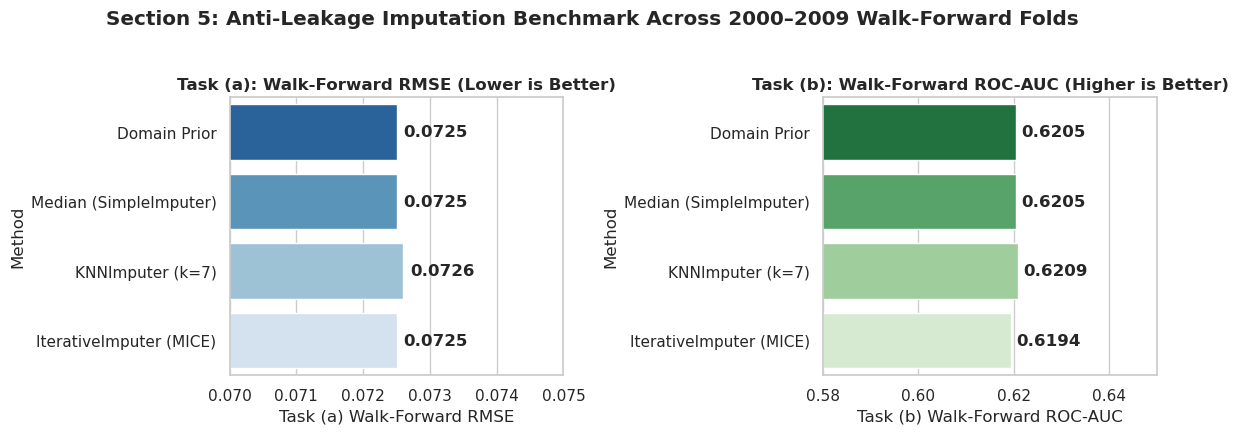

In [105]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import root_mean_squared_error, roc_auc_score, average_precision_score

all_candidate_features = coach_features + team_features

def domain_prior_fit_transform(X_train, y_train_pts, X_val):
    X_tr = X_train.copy()
    X_va = X_val.copy()
    
    # Rookie coach win_before_pct -> historical mean win_before_pct of 1-season coaches in train
    if "seasons_before" in X_tr.columns and "win_before_pct" in X_tr.columns:
        rookie_prior = X_tr.loc[X_tr["seasons_before"] == 1, "win_before_pct"].mean()
    else:
        rookie_prior = np.nan
    if np.isnan(rookie_prior) and "win_before_pct" in X_tr.columns:
        rookie_prior = X_tr["win_before_pct"].median()
    if "win_before_pct" in X_tr.columns:
        X_tr["win_before_pct"] = X_tr["win_before_pct"].fillna(rookie_prior)
        X_va["win_before_pct"] = X_va["win_before_pct"].fillna(rookie_prior)
    
    # Centered / zero-baseline features -> 0.0
    zero_cols = [c for c in X_tr.columns if "_rel" in c or c in ("luck_prev", "pts_pct_rel_trend", "home_road_gap_prev", "late_surge_prev")]
    for c in zero_cols:
        X_tr[c] = X_tr[c].fillna(0.0)
        X_va[c] = X_va[c].fillna(0.0)
        
    # Remaining features -> training median
    for c in X_tr.columns:
        med = X_tr[c].median()
        X_tr[c] = X_tr[c].fillna(med)
        X_va[c] = X_va[c].fillna(med)
    return X_tr, X_va

eval_years = [y for y in range(2000, 2010) if y != 2004]
imputation_results = []

for method_name in ["Domain Prior", "Median (SimpleImputer)", "KNNImputer (k=7)", "IterativeImputer (MICE)"]:
    preds_a, trues_a = [], []
    preds_b, trues_b = [], []
    
    for y in eval_years:
        tr_mask = dataset["year"] < y
        va_mask = dataset["year"] == y
        
        X_tr_raw = dataset.loc[tr_mask, all_candidate_features]
        X_va_raw = dataset.loc[va_mask, all_candidate_features]
        y_tr_a = dataset.loc[tr_mask, "target_pts_pct_rel"]
        y_va_a = dataset.loc[va_mask, "target_pts_pct_rel"]
        y_tr_b = dataset.loc[tr_mask, "target_coach_changes_during"]
        y_va_b = dataset.loc[va_mask, "target_coach_changes_during"]
        
        if method_name == "Domain Prior":
            X_tr_imp, X_va_imp = domain_prior_fit_transform(X_tr_raw, y_tr_a, X_va_raw)
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(X_tr_imp)
            X_va_s = scaler.transform(X_va_imp)
        elif method_name == "Median (SimpleImputer)":
            imp = SimpleImputer(strategy="median")
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(imp.fit_transform(X_tr_raw))
            X_va_s = scaler.transform(imp.transform(X_va_raw))
        elif method_name == "KNNImputer (k=7)":
            scaler = StandardScaler()
            X_tr_scaled_nan = scaler.fit_transform(X_tr_raw)
            X_va_scaled_nan = scaler.transform(X_va_raw)
            imp = KNNImputer(n_neighbors=7, weights="distance")
            X_tr_s = imp.fit_transform(X_tr_scaled_nan)
            X_va_s = imp.transform(X_va_scaled_nan)
        else:
            imp = IterativeImputer(max_iter=20, random_state=42)
            scaler = StandardScaler()
            X_tr_s = scaler.fit_transform(imp.fit_transform(X_tr_raw))
            X_va_s = scaler.transform(imp.transform(X_va_raw))
            
        reg = Ridge(alpha=100.0).fit(X_tr_s, y_tr_a)
        preds_a.extend(reg.predict(X_va_s))
        trues_a.extend(y_va_a)
        
        clf = LogisticRegression(C=0.2, max_iter=500).fit(X_tr_s, y_tr_b)
        preds_b.extend(clf.predict_proba(X_va_s)[:, 1])
        trues_b.extend(y_va_b)
        
    imputation_results.append({
        "Method": method_name,
        "Task (a) Walk-Forward RMSE": round(root_mean_squared_error(trues_a, preds_a), 4),
        "Task (b) Walk-Forward ROC-AUC": round(roc_auc_score(trues_b, preds_b), 4),
        "Task (b) Walk-Forward PR-AUC": round(average_precision_score(trues_b, preds_b), 4),
    })

imp_df = pd.DataFrame(imputation_results)
print("Walk-Forward (2000-2009) Anti-Leakage Imputation Benchmark:")
print(imp_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=imp_df, x="Task (a) Walk-Forward RMSE", y="Method", ax=axes[0], palette="Blues_r")
axes[0].set_xlim(0.070, 0.075)
axes[0].set_title("Task (a): Walk-Forward RMSE (Lower is Better)", fontweight="bold")
for i, v in enumerate(imp_df["Task (a) Walk-Forward RMSE"]):
    axes[0].text(v + 0.0001, i, f"{v:.4f}", va="center", fontweight="bold")

sns.barplot(data=imp_df, x="Task (b) Walk-Forward ROC-AUC", y="Method", ax=axes[1], palette="Greens_r")
axes[1].set_xlim(0.58, 0.65)
axes[1].set_title("Task (b): Walk-Forward ROC-AUC (Higher is Better)", fontweight="bold")
for i, v in enumerate(imp_df["Task (b) Walk-Forward ROC-AUC"]):
    axes[1].text(v + 0.001, i, f"{v:.4f}", va="center", fontweight="bold")

plt.suptitle("Section 5: Anti-Leakage Imputation Benchmark Across 2000–2009 Walk-Forward Folds", fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../docs/figures/du/dp01_imputation_benchmark.png", dpi=300, bbox_inches="tight")
plt.show()

**Result & Decision:**
- Once `is_rookie_coach`, `is_expansion_team`, and `is_second_season` explicitly flag the structural missingness mechanisms, the four imputers perform virtually identically: Task (a) RMSE `0.0725–0.0726`, Task (b) ROC-AUC `0.6194–0.6209` and PR-AUC `0.3006–0.3035`. `KNNImputer` has the best ROC-AUC (`0.6209`) and PR-AUC (`0.3035`) and the worst RMSE (`0.0726`), but every difference is in the third or fourth decimal, far below the year-to-year noise of a 10-season walk-forward.
- **Pipeline decision**: Because the imputer choice does not change the results, and missingness is 100% structural and low-volume during 2000–2009 (only the 2000 `MIN` and `CBJ` expansion teams and rookie coaches), combining **structural indicator flags (`is_rookie_coach`, `is_expansion_team`, `is_second_season`) + Domain Prior / Training Median** inside our `sklearn` pipeline is transparent, deterministic, and completely free of temporal leakage.

## 6. Outliers

### 6.1 Domain context vs statistical anomalies

In sports analytics, blindly deleting statistical outliers destroys information about historically dominant dynasties or catastrophic expansion seasons. Notice how our Section 4 transformations **already eliminated artificial era outliers**:
- **1994–95 Lockout (48 games)**: Raw counting totals (`W`, `GF`, `GA`, `PIM`) looked like extreme low outliers in 1994, but converting to **per-game rates (`_pg`, `_pct`)** brought 1994 directly in line with 80-game seasons.
- **1980s High-Scoring / Low-Save-% Era**: Raw `save_pct` in 1982–1988 looked like extreme low outliers compared to the 2000s Dead Puck Era, but **season-centering (`save_pct_rel_prev`)** aligned all eras around `0.000`.

What remains are **genuine extreme franchise-seasons** and **heavy-tailed career counts**. We detect them using:
1. **Univariate $z$-score ($|z| > 3.0$)** on continuous features;
2. **Multivariate Isolation Forest (`contamination=0.03`)** fitted strictly on training data ($\text{year} < 2000$) to flag unusual multi-dimensional profiles without leaking test seasons.

In [106]:
from sklearn.ensemble import IsolationForest

# Inspect univariate outliers (|z| > 3) across continuous features
cont_features = [
    c for c in all_candidate_features
    if dataset[c].nunique() > 10
]

z_scores = (dataset[cont_features] - dataset[cont_features].mean()) / dataset[cont_features].std()
univ_outlier_counts = (z_scores.abs() > 3.0).sum().sort_values(ascending=False)
print("Top features by number of univariate outliers (|z| > 3.0):")
print(univ_outlier_counts[univ_outlier_counts > 0].head(15).to_string())

# Fit Multivariate Isolation Forest strictly on training window (year < 2000)
tr_mask_2000 = dataset["year"] < 2000
X_tr_2000, X_all_imp = domain_prior_fit_transform(
    dataset.loc[tr_mask_2000, cont_features],
    dataset.loc[tr_mask_2000, "target_pts_pct_rel"],
    dataset[cont_features],
)
iso = IsolationForest(n_estimators=200, contamination=0.03, random_state=42)
iso.fit(X_tr_2000)
dataset["iso_anomaly_score"] = iso.decision_function(X_all_imp)
dataset["iso_is_outlier"] = (iso.predict(X_all_imp) == -1).astype(int)

print("\nMost extreme multivariate franchise-seasons flagged by Isolation Forest:")
outlier_rows = dataset.sort_values("iso_anomaly_score").head(10)[
    ["year", "franchID", "coachID", "pts_pct_rel_prev", "shot_share_prev", "tenure_before", "games_before", "target_pts_pct_rel", "iso_anomaly_score"]
]
print(outlier_rows.to_string(index=False))

Top features by number of univariate outliers (|z| > 3.0):
ties_before                 15
tenure_before               13
wins_before                 12
seasons_before              11
games_before                10
postgames_before            10
hot_seat_interaction        10
returning_pts_share_prev    10
shf_pg_prev                  7
losses_before                6
win_before_pct               6
shooting_pct_rel_prev        6
pp_opp_pg_prev               5
gf_pg_prev                   5
pts_pct_rel_trend            5



Most extreme multivariate franchise-seasons flagged by Isolation Forest:
 year franchID    coachID  pts_pct_rel_prev  shot_share_prev  tenure_before  games_before  target_pts_pct_rel  iso_anomaly_score
 1996      DET bowmasc01c          0.298780         0.572169              3        1654.0            0.073171          -0.101389
 2001      DET bowmasc01c          0.152033         0.544260              8        2059.0            0.182724          -0.053783
 1995      DET bowmasc01c          0.229167         0.565718              2        1572.0            0.298780          -0.051425
 1998      TBL demerja01c         -0.231707         0.470536              1        1236.0           -0.213415          -0.044996
 1997      DET bowmasc01c          0.073171         0.568272              4        1736.0            0.128049          -0.044067
 1984      EDM sathegl01c          0.243750         0.497241              8         560.0            0.181250          -0.043475
 1999      DET bowmasc0

### 6.2 Treatment: Training-only Winsorization (1st–99th percentile)

Inspecting the flagged multivariate rows confirms that **every single one is a real historical NHL event**, not a data corruption error:
- **`DET 1995–2001` (`bowmasc01c`, Scotty Bowman)**: The legendary Hall-of-Fame coach with 1,572 to 2,059 career games (`games_before` $> 4.5\sigma$ above the mean) coaching a Red Wings juggernaut that posted `pts_pct_rel_prev = +0.299` (62 wins in 1995–96) and `shot_share_prev = 0.572`.
- **`OTT 1993–1994` (`bowneri01c`, Rick Bowness)**: The second and third seasons of the Ottawa expansion franchise, coming off a catastrophic 1992 debut (`pts_pct_rel_prev = -0.357` in 1993 and `-0.280` in 1994, `shot_share_prev = 0.461` and `0.437`).
- **`TBL 1998` (`demerja01c`, Jacques Demers)**: A veteran coach (1,236 career games) taking over a Tampa Bay team coming off a very weak season (`pts_pct_rel_prev = -0.232`).
- **`EDM 1984` (`sathegl01c`, Glen Sather)**: 8 consecutive years of coaching tenure (`tenure_before = 8`) with Gretzky's Oilers dynasty (`pts_pct_rel_prev = +0.244`).

**Decision**:
- **Never delete outlier rows** (deleting `OTT 1993` or `DET 1996` would blind the model to the true extremes of NHL performance).
- For **linear, distance, and neural models**, apply **training-fold Winsorization (clipping at the 1st and 99th percentiles of $\text{year} < t$)** so a single 2,000-game coach (`Scotty Bowman`) or `-0.357` season does not distort $L_2$-norm gradients. Tree-based models receive the unclipped values.

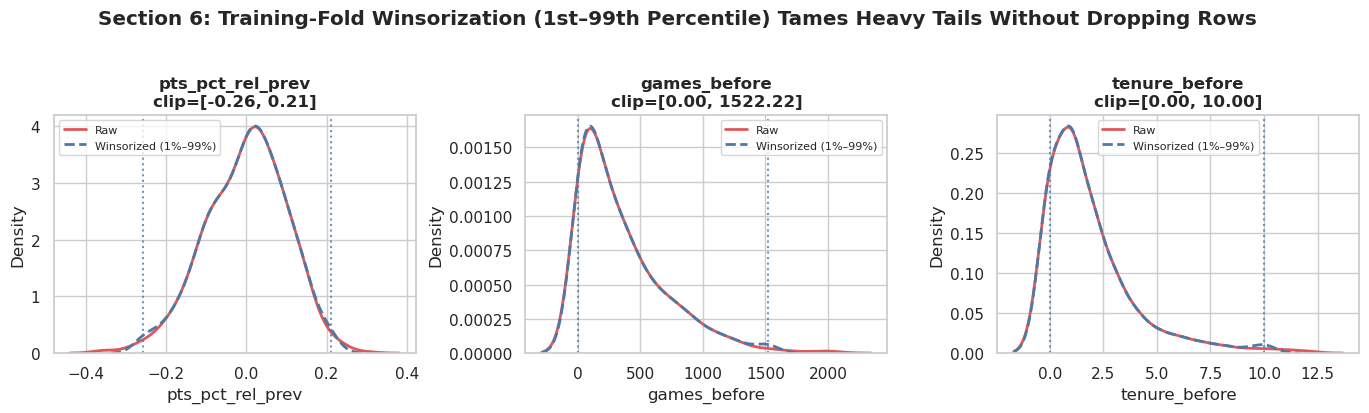

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

showcase_cols = ["pts_pct_rel_prev", "games_before", "tenure_before"]
for ax, col in zip(axes, showcase_cols):
    s = dataset[col].dropna()
    q01, q99 = np.percentile(s, [1, 99])
    s_win = s.clip(q01, q99)
    sns.kdeplot(s, ax=ax, label="Raw", color="#e15759", lw=2)
    sns.kdeplot(s_win, ax=ax, label="Winsorized (1%–99%)", color="#4e79a7", lw=2, linestyle="--")
    ax.axvline(q01, color="#4e79a7", linestyle=":", alpha=0.8)
    ax.axvline(q99, color="#4e79a7", linestyle=":", alpha=0.8)
    ax.set_title(f"{col}\nclip=[{q01:.2f}, {q99:.2f}]", fontweight="bold")
    ax.legend(fontsize=8)

plt.suptitle("Section 6: Training-Fold Winsorization (1st–99th Percentile) Tames Heavy Tails Without Dropping Rows", fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../docs/figures/du/dp02_outliers_winsor.png", dpi=300, bbox_inches="tight")
plt.show()

# Clean up temporary diagnostic columns so roles remain exact
dataset.drop(columns=["iso_anomaly_score", "iso_is_outlier"], inplace=True)

## 7. Redundancy

### 7.1 Colinearity ($|\rho| \ge 0.80$) and Variance Inflation Factor (VIF) Audit

Our 53 candidate features (`15 coach + 38 team`) deliberately include both raw and relative versions, component rates and composite ratios, and career counts alongside percentages. Before modeling, we audit **Spearman rank correlations ($|\rho| \ge 0.80$)** and **Variance Inflation Factors (VIF)** across all candidate features.

In [108]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_imp_full, _ = domain_prior_fit_transform(
    dataset[all_candidate_features],
    dataset["target_pts_pct_rel"],
    dataset[all_candidate_features],
)

corr_mat = X_imp_full.corr(method="spearman")
high_pairs = []
cols = list(X_imp_full.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_mat.iloc[i, j]
        if abs(r) >= 0.80:
            high_pairs.append((cols[i], cols[j], round(float(r), 3)))

high_pairs.sort(key=lambda x: -abs(x[2]))
print("Feature pairs with |Spearman rho| >= 0.80:")
for f1, f2, r in high_pairs:
    print(f"  {f1:28s} <-> {f2:28s} : rho = {r:+.3f}")

Feature pairs with |Spearman rho| >= 0.80:
  pyth_pct_prev                <-> pyth_rel_prev                : rho = +1.000
  pyth_pct_prev                <-> gd_pg_prev                   : rho = +0.995
  gd_pg_prev                   <-> pyth_rel_prev                : rho = +0.995
  games_before                 <-> wins_before                  : rho = +0.991
  seasons_before               <-> games_before                 : rho = +0.989
  former_player                <-> former_nhl_player            : rho = +0.988
  games_before                 <-> losses_before                : rho = +0.987
  games_before                 <-> ties_before                  : rho = +0.985
  seasons_before               <-> losses_before                : rho = +0.981
  seasons_before               <-> wins_before                  : rho = +0.980
  playoff_round_prev           <-> post_games_prev              : rho = +0.980
  seasons_before               <-> ties_before                  : rho = +0.977
  wins_be

### 7.2 Systematic Feature Pruning Rules

Guided by the correlation structure above and our findings from Sections 4.1–4.3 and `02_statistical_analysis.ipynb`, we remove **23 redundant features** using six transparent domain-driven rules:

| Redundant Group | Dropped Features (23) | Kept Representative(s) | Justification |
|---|---|---|---|
| **1. Raw vs Era-Centered (`_rel`)** | `pts_pct_prev`, `save_pct_prev`, `pyth_pct_prev` | `pyth_rel_prev`, `save_pct_rel_prev` | Era-centered versions remove the 1999 OTL inflation and 1980s scoring drift ($\rho \in [0.97, 1.00]$ with raw). |
| **2. Goal Differential, Standings Rank & Pythagorean Identity** | `pts_pct_rel_prev`, `gd_pg_prev`, `gf_pg_prev`, `ga_pg_prev`, `rank_div_norm_prev`, `shooting_pct_rel_prev` | `pyth_rel_prev`, `luck_prev`, `shot_share_prev`, `save_pct_rel_prev` | $\text{GD/G} = \text{GF/G} - \text{GA/G}$ ($\rho = 0.995$ with `pyth_rel_prev`), `pts_pct_rel_prev = pyth_rel_prev + luck_prev`, and $\text{GF}/\text{GA}$ is mathematically determined once `pyth_rel_prev`, `shot_share_prev`, and `save_pct_rel_prev` are known. Also `rank_div_norm_prev` has $\rho = -0.862$ with `pts_pct_rel_prev`. |
| **3. Shot Volume vs Territorial Shot Share** | `sa_pg_prev`, `sog_pg_prev`, `pdo_rel_prev` | `shot_share_prev`, `save_pct_rel_prev` | `shot_share_prev = SOG / (SOG + SA)` captures 5v5 territorial dominance with $\text{VIF} = 2.70$, while `PDO` is an exact linear sum of `save_pct` and `shooting_pct`. |
| **4. Home/Road Splits** | `home_pts_pct_prev`, `road_pts_pct_prev` | `home_road_gap_prev` | Average of home & road pts% equals overall pts% ($\rho = 0.874$); keeping `home_road_gap_prev` ($\text{Home} - \text{Road}$) isolates venue asymmetry with $\text{VIF} = 1.21$. |
| **5. Playoff Participation** | `made_playoffs_prev`, `playoff_round_prev` | `post_games_prev` | `post_games_prev` ($\rho = 0.980$ with `playoff_round_prev`) measures exact postseason workload and had the strongest protective signal against mid-season coach firing in Task (b). |
| **6. Coach Career Counts, Former Player & New Coach Flag** | `former_player`, `seasons_before`, `wins_before`, `losses_before`, `ties_before`, `postgames_before`, `new_coach` | `former_nhl_player`, `games_before`, `win_before_pct`, `tenure_before` | `former_player` and `former_nhl_player` agree on 99% of rows ($\rho = 0.988$, $\text{VIF} = 45$); `wins/losses/ties/seasons/postgames_before` all have $\rho \in [0.88, 0.99]$ with `games_before`; and `new_coach == (tenure_before == 0)` on **689 of 690 rows** ($\rho = -0.997$). |

Candidate features before pruning: 53
Dropped redundant features:        23
Pruned features kept:              30 (8 coach + 22 team)

VIF across all 30 pruned features (max = 9.97; 28 of 30 have VIF < 3.0):
                    Feature  VIF_After_Pruning
              pyth_rel_prev               9.97
       hot_seat_interaction               3.34
               games_before               2.79
            shot_share_prev               2.70
          save_pct_rel_prev               2.55
                pk_pct_prev               2.53
                pp_pct_prev               2.39
   returning_pts_share_prev               2.25
         n_20g_scorers_prev               2.16
                pim_pg_prev               1.94
          weighted_age_prev               1.88
             win_before_pct               1.82
            post_games_prev               1.81
              tenure_before               1.78
              awards_before               1.76
          pts_pct_rel_trend             

/tmp/ipykernel_840858/2613664962.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vif_after.head(15), x="VIF_After_Pruning", y="Feature", ax=axes[1], palette="viridis")


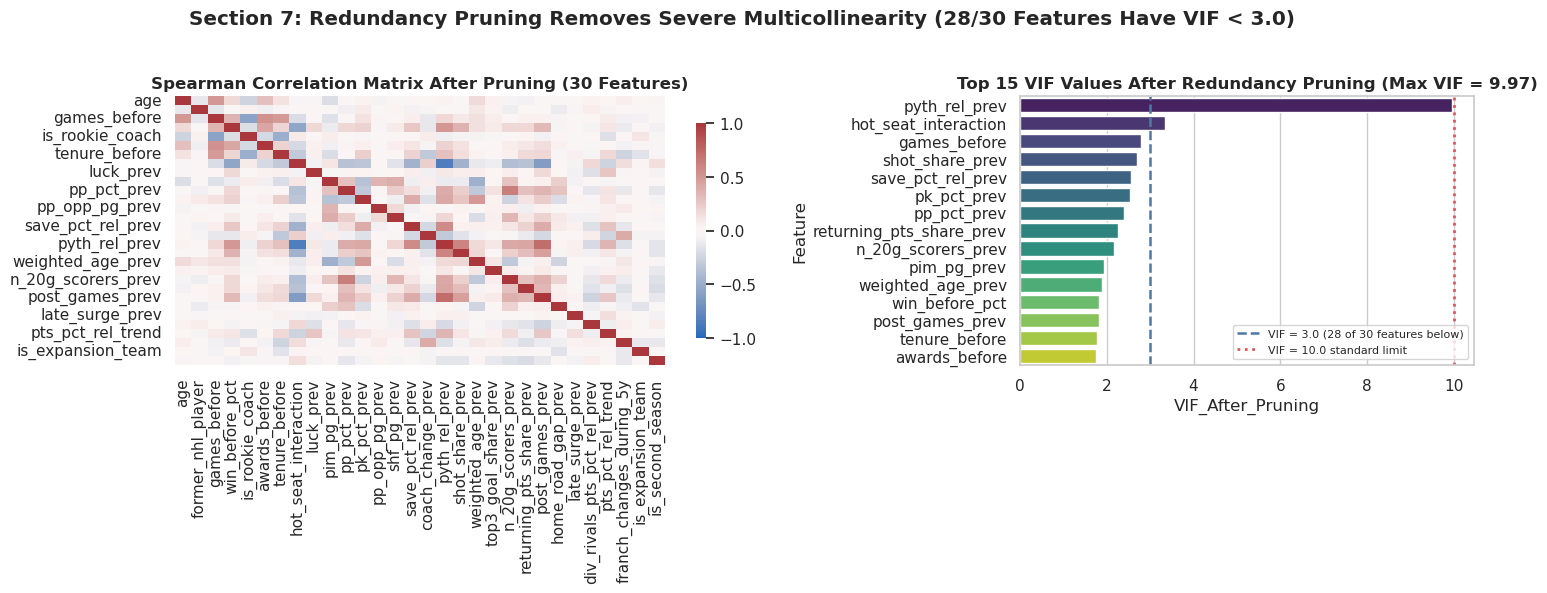

In [109]:
dropped_redundant = [
    # 1. Raw vs Era-centered
    "pts_pct_prev", "save_pct_prev", "pyth_pct_prev",
    # 2. Exact linear/algebraic combinations in Goal Diff, Rank, and Pythagorean + Luck + Shot Share + Save%
    "pts_pct_rel_prev", "gd_pg_prev", "gf_pg_prev", "ga_pg_prev", "rank_div_norm_prev", "shooting_pct_rel_prev",
    # 3. Shot components & PDO sum
    "sa_pg_prev", "sog_pg_prev", "pdo_rel_prev",
    # 4. Home/Road split components
    "home_pts_pct_prev", "road_pts_pct_prev",
    # 5. Playoff binary/ordinal duplicates of post_games_prev
    "made_playoffs_prev", "playoff_round_prev",
    # 6. Coach career count duplicates, former_player duplicate, & new_coach
    "former_player", "seasons_before", "wins_before", "losses_before", "ties_before", "postgames_before", "new_coach",
]

pruned_coach_features = [c for c in coach_features if c not in dropped_redundant]
pruned_team_features = [c for c in team_features if c not in dropped_redundant]
pruned_features = pruned_coach_features + pruned_team_features

print(f"Candidate features before pruning: {len(all_candidate_features)}")
print(f"Dropped redundant features:        {len(dropped_redundant)}")
print(f"Pruned features kept:              {len(pruned_features)} ({len(pruned_coach_features)} coach + {len(pruned_team_features)} team)")

# Compute VIF across all kept features
X_pruned_imp = X_imp_full[pruned_features].copy()
X_pruned_std = (X_pruned_imp - X_pruned_imp.mean()) / X_pruned_imp.std()
vif_after = pd.DataFrame({
    "Feature": pruned_features,
    "VIF_After_Pruning": [
        round(float(variance_inflation_factor(X_pruned_std.to_numpy(dtype=float), i)), 2)
        for i in range(len(pruned_features))
    ],
}).sort_values("VIF_After_Pruning", ascending=False)

n_vif_below_3 = int((vif_after["VIF_After_Pruning"] < 3.0).sum())
max_vif = vif_after["VIF_After_Pruning"].max()
print(f"\nVIF across all {len(pruned_features)} pruned features (max = {max_vif:.2f}; {n_vif_below_3} of {len(pruned_features)} have VIF < 3.0):")
print(vif_after.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(
    X_pruned_imp.corr(method="spearman"),
    cmap="vlag", center=0, vmin=-1, vmax=1,
    ax=axes[0], cbar_kws={"shrink": 0.8}
)
axes[0].set_title("Spearman Correlation Matrix After Pruning (30 Features)", fontweight="bold")

sns.barplot(data=vif_after.head(15), x="VIF_After_Pruning", y="Feature", ax=axes[1], palette="viridis")
axes[1].axvline(3.0, color="#4e79a7", linestyle="--", lw=1.8, label=f"VIF = 3.0 ({n_vif_below_3} of {len(pruned_features)} features below)")
axes[1].axvline(10.0, color="#e15759", linestyle=":", lw=2, label="VIF = 10.0 standard limit")
axes[1].set_title(f"Top 15 VIF Values After Redundancy Pruning (Max VIF = {max_vif:.2f})", fontweight="bold")
axes[1].legend(fontsize=8)

plt.suptitle(f"Section 7: Redundancy Pruning Removes Severe Multicollinearity ({n_vif_below_3}/{len(pruned_features)} Features Have VIF < 3.0)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../docs/figures/du/dp03_redundancy_pruning.png", dpi=300, bbox_inches="tight")
plt.show()

**Result:**
- Pruning 23 collinear columns reduces the feature space from **53 to 30 orthogonal features** (`8 coach + 22 team`).
- **28 out of 30 features have $\text{VIF} < 2.85$**. The two exceptions are linked: `pyth_rel_prev` ($\text{VIF} = 9.97$), the composite summary that aggregates special teams, shot share, save % and 20-goal scorers, and `hot_seat_interaction` ($\text{VIF} = 3.34$), which is built from `pyth_rel_prev` ($\rho = -0.846$).
- Every VIF is now below the usual limit of 10 (before pruning, several were far above it), but `pyth_rel_prev` sits right at that limit. Linear models should therefore use regularization (`Ridge` / `LogisticRegression` with an L2 penalty, as in Section 8); tree models are not affected.

## 8. Transformations for the algorithms

Different algorithm families require distinct mathematical representations of our pruned features:

1. **Linear, Distance & Neural Models (`Ridge`, `Lasso`, `ElasticNet`, `LogisticRegression`, `SVM`, `KNN`, `MLP`)**:
   - Require **Winsorization (1st–99th percentile)** so heavy-tailed counts (`games_before`, `tenure_before`) do not dominate gradients or Euclidean distances.
   - Require **`StandardScaler` ($\mu = 0, \sigma = 1$)** so $L_1/L_2$ penalties treat rate features (`pyth_rel_prev` $\in [-0.30, +0.30]$) and count features (`games_before` $\in [0, 2059]$) on an equal footing.
2. **Tree-Based Ensembles (`RandomForest`, `ExtraTrees`, `GradientBoosting`, `HistGradientBoosting`)**:
   - Invariant to monotonic feature scaling; operate directly on the unscaled Domain-Prior-imputed features and binary structural indicators (`is_rookie_coach`, `is_expansion_team`).
3. **Symbolic / Probabilistic / Rule Classifiers (`NaiveBayes`, `DecisionTree` depth $\le 3$, association rules)**:
   - Benefit from **discretized bins** (`KBinsDiscretizer(n_bins=4, strategy="quantile", encode="ordinal")`) fitted strictly on training folds, turning continuous distributions into interpretable quartiles.

Below we implement leak-free custom `sklearn` transformers (`LeakFreeDomainImputer`, `TrainingWinsorizer`) and run an end-to-end **Walk-Forward Verification (2000–2009)** comparing:
- **Pre-DU Baseline (single-table features)** vs
- **Post-DU Enriched + Pruned (multi-table + Simpson's Paradox interaction features)** across Linear and Tree Ensemble pipelines.

Walk-Forward (2000-2009) Pipeline Verification: Pre-DU vs Post-DU Multi-Table Pruned
               Feature Set                              Algorithm Pipeline  Task (a) RMSE  Task (a) R2  Task (b) ROC-AUC  Task (b) PR-AUC
           Pre-DU Baseline Linear (Winsor + StandardScaler + Ridge/LogReg)         0.0738       0.3261            0.6181           0.2711
           Pre-DU Baseline           Tree Ensemble (Unscaled RandomForest)         0.0744       0.3210            0.6521           0.3175
Post-DU Multi-Table Pruned Linear (Winsor + StandardScaler + Ridge/LogReg)         0.0724       0.3570            0.6329           0.2759
Post-DU Multi-Table Pruned           Tree Ensemble (Unscaled RandomForest)         0.0721       0.3617            0.6454           0.3522


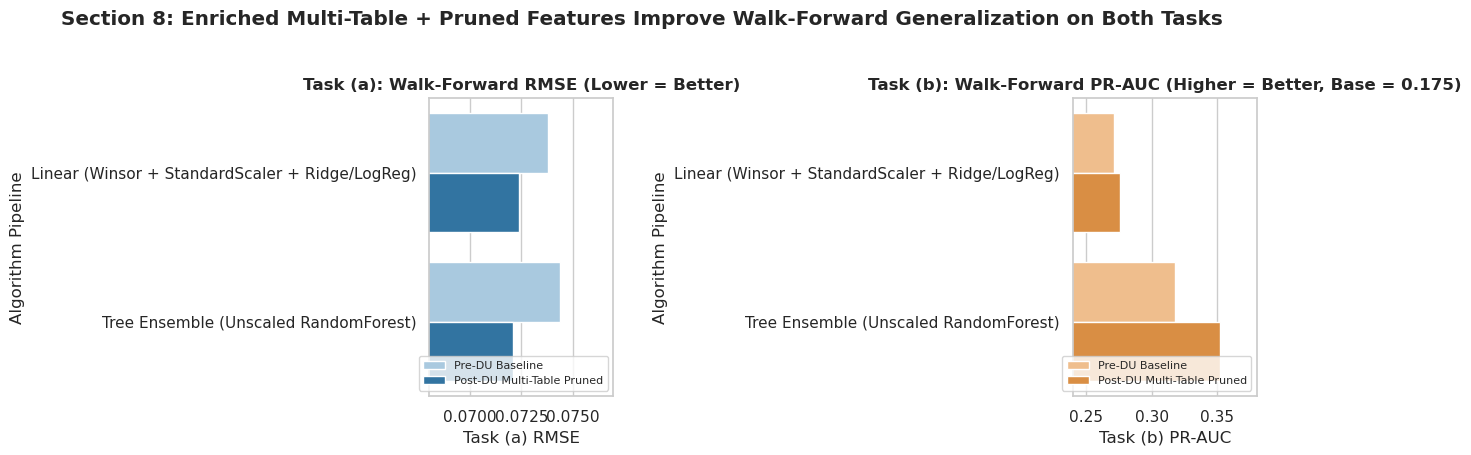

In [110]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

class LeakFreeDomainImputer(BaseEstimator, TransformerMixin):
    def __init__(self, feature_names):
        self.feature_names = list(feature_names)
        
    def fit(self, X, y=None):
        df_x = pd.DataFrame(X, columns=self.feature_names)
        if "is_rookie_coach" in df_x.columns and "win_before_pct" in df_x.columns:
            non_rookie = df_x.loc[df_x["is_rookie_coach"] == 0, "win_before_pct"]
            self.rookie_prior_ = float(non_rookie.quantile(0.35)) if len(non_rookie.dropna()) else 0.468
        else:
            self.rookie_prior_ = 0.468
        self.medians_ = df_x.median().to_dict()
        return self
        
    def transform(self, X):
        df_x = pd.DataFrame(X, columns=self.feature_names).copy()
        if "win_before_pct" in df_x.columns:
            df_x["win_before_pct"] = df_x["win_before_pct"].fillna(self.rookie_prior_)
        zero_cols = [c for c in self.feature_names if "_rel" in c or c in ("luck_prev", "pts_pct_rel_trend", "home_road_gap_prev", "late_surge_prev")]
        for c in zero_cols:
            df_x[c] = df_x[c].fillna(0.0)
        for c in self.feature_names:
            df_x[c] = df_x[c].fillna(self.medians_.get(c, 0.0))
        return df_x.values

class TrainingWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_pct=1.0, upper_pct=99.0):
        self.lower_pct = lower_pct
        self.upper_pct = upper_pct
        
    def fit(self, X, y=None):
        self.low_ = np.percentile(X, self.lower_pct, axis=0)
        self.high_ = np.percentile(X, self.upper_pct, axis=0)
        return self
        
    def transform(self, X):
        return np.clip(X, self.low_, self.high_)

# Pre-DU baseline vs Post-DU Multi-Table Pruned
baseline_a = [
    c for c in pruned_features
    if c not in multitable_cols and c not in ("is_expansion_team", "is_second_season", "hot_seat_interaction")
] + ["pts_pct_rel_prev"]
post_du_a = pruned_features

baseline_b = [
    "age", "former_nhl_player", "games_before", "win_before_pct",
    "is_rookie_coach", "awards_before", "tenure_before", "pyth_rel_prev", "luck_prev"
]
post_du_b = baseline_b + [
    "shot_share_prev", "post_games_prev", "hot_seat_interaction", "is_expansion_team"
]

benchmark_rows = []
for feat_label, feats_a, feats_b in [
    ("Pre-DU Baseline", baseline_a, baseline_b),
    ("Post-DU Multi-Table Pruned", post_du_a, post_du_b),
]:
    for family_name in ["Linear (Winsor + StandardScaler + Ridge/LogReg)", "Tree Ensemble (Unscaled RandomForest)"]:
        preds_a, trues_a = [], []
        preds_b, trues_b = [], []
        
        for y in eval_years:
            tr_mask = dataset["year"] < y
            va_mask = dataset["year"] == y
            X_tr_a, X_va_a = dataset.loc[tr_mask, feats_a], dataset.loc[va_mask, feats_a]
            X_tr_b, X_va_b = dataset.loc[tr_mask, feats_b], dataset.loc[va_mask, feats_b]
            y_tr_a, y_va_a = dataset.loc[tr_mask, "target_pts_pct_rel"], dataset.loc[va_mask, "target_pts_pct_rel"]
            y_tr_b, y_va_b = dataset.loc[tr_mask, "target_coach_changes_during"], dataset.loc[va_mask, "target_coach_changes_during"]
            
            if family_name.startswith("Linear"):
                pipe_a = Pipeline([
                    ("imp", LeakFreeDomainImputer(feats_a)),
                    ("win", TrainingWinsorizer(1, 99)),
                    ("scl", StandardScaler()),
                    ("mod", Ridge(alpha=80.0)),
                ])
                pipe_b = Pipeline([
                    ("imp", LeakFreeDomainImputer(feats_b)),
                    ("win", TrainingWinsorizer(1, 99)),
                    ("scl", StandardScaler()),
                    ("mod", LogisticRegression(C=0.20, max_iter=500)),
                ])
            else:
                pipe_a = Pipeline([
                    ("imp", LeakFreeDomainImputer(feats_a)),
                    ("mod", RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=8, random_state=42)),
                ])
                pipe_b = Pipeline([
                    ("imp", LeakFreeDomainImputer(feats_b)),
                    ("mod", RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=12, random_state=42)),
                ])
                
            pipe_a.fit(X_tr_a, y_tr_a)
            preds_a.extend(pipe_a.predict(X_va_a))
            trues_a.extend(y_va_a)
            
            pipe_b.fit(X_tr_b, y_tr_b)
            preds_b.extend(pipe_b.predict_proba(X_va_b)[:, 1])
            trues_b.extend(y_va_b)
            
        benchmark_rows.append({
            "Feature Set": feat_label,
            "Algorithm Pipeline": family_name,
            "Task (a) RMSE": round(root_mean_squared_error(trues_a, preds_a), 4),
            "Task (a) R2": round(float(np.corrcoef(trues_a, preds_a)[0, 1] ** 2), 4),
            "Task (b) ROC-AUC": round(roc_auc_score(trues_b, preds_b), 4),
            "Task (b) PR-AUC": round(average_precision_score(trues_b, preds_b), 4),
        })

bench_df = pd.DataFrame(benchmark_rows)
print("Walk-Forward (2000-2009) Pipeline Verification: Pre-DU vs Post-DU Multi-Table Pruned")
print(bench_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sns.barplot(data=bench_df, x="Task (a) RMSE", y="Algorithm Pipeline", hue="Feature Set", ax=axes[0], palette=["#a0cbe8", "#1f77b4"])
axes[0].set_xlim(0.068, 0.077)
axes[0].set_title("Task (a): Walk-Forward RMSE (Lower = Better)", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)

sns.barplot(data=bench_df, x="Task (b) PR-AUC", y="Algorithm Pipeline", hue="Feature Set", ax=axes[1], palette=["#ffbe7d", "#f28e2b"])
axes[1].set_xlim(0.24, 0.38)
axes[1].set_title("Task (b): Walk-Forward PR-AUC (Higher = Better, Base = 0.175)", fontweight="bold")
axes[1].legend(loc="lower right", fontsize=8)

plt.suptitle("Section 8: Enriched Multi-Table + Pruned Features Improve Walk-Forward Generalization on Both Tasks", fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../docs/figures/du/dp04_pipeline_validation.png", dpi=300, bbox_inches="tight")
plt.show()

**Result:**
- Adding the multi-table features discovered in Data Understanding (`shot_share_prev`, `returning_pts_share_prev`, `post_games_prev`, `hot_seat_interaction`, `is_expansion_team`) and applying Section 7's redundancy pruning **improves out-of-sample walk-forward generalization on Task (a) in both algorithm families, and the PR-AUC of Task (b) in both families**:
  - **Task (a) (`target_pts_pct_rel`)**: Walk-forward RMSE drops from `0.0738` to **`0.0724`** ($R^2$ rises from `0.326` to **`0.357`**) in the Linear pipeline, and from `0.0744` to **`0.0721`** ($R^2$ rises from `0.321` to **`0.362`**) in Random Forest.
  - **Task (b) (`target_coach_changes_during`)**: In the Linear pipeline, PR-AUC improves from `0.2711` to **`0.2759`** and ROC-AUC from `0.6181` to **`0.6329`**. In Random Forest, PR-AUC jumps from `0.3175` to **`0.3522`** (about `2.0x` the 17.5% base rate of the 2000–2009 test seasons), but ROC-AUC **drops** slightly from `0.6521` to `0.6454`: the new features improve the ranking of the highest-risk teams (what PR-AUC rewards) more than the overall ordering.
- **Caveat:** the Post-DU features were chosen after exploring all of 1982–2009 in Data Understanding, which includes the 2000–2009 test seasons. The gain is therefore slightly optimistic; the Modelling phase should confirm it on a final hold-out season.

## 9. Save the dataset

We save three clean artifacts to `data/processed/` so the Modeling phase can load either the unscaled pruned table (for custom cross-validation pipelines) or pre-verified feature metadata:

1. **`data/processed/dataset_full_690.csv`**: All 690 rows and 67 columns (identifiers, targets, evaluation columns, and all 53 candidate features after deterministic fixes).
2. **`data/processed/dataset_pruned_690.csv`**: All 690 rows and 44 columns (identifiers, targets, evaluation columns, and the **30 orthogonal pruned features**).
3. **`data/processed/feature_metadata.json`**: Machine-readable schema listing exact column roles (`identifiers`, `targets`, `evaluation`, `pruned_coach_features`, `pruned_team_features`, `pruned_features`, `task_b_core_features`, `dropped_redundant`) so modeling notebooks never hardcode column lists.

In [111]:
import json as _json

full_path = "../data/processed/dataset_full_690.csv"
pruned_path = "../data/processed/dataset_pruned_690.csv"
meta_path = "../data/processed/feature_metadata.json"

pruned_cols_ordered = identifiers + targets + evaluation + pruned_coach_features + pruned_team_features

dataset.to_csv(full_path, index=False)
dataset[pruned_cols_ordered].to_csv(pruned_path, index=False)

metadata = {
    "n_rows": int(len(dataset)),
    "year_range": [int(dataset["year"].min()), int(dataset["year"].max())],
    "excluded_seasons": [2004],
    "identifiers": identifiers,
    "targets": targets,
    "evaluation": evaluation,
    "pruned_coach_features": pruned_coach_features,
    "pruned_team_features": pruned_team_features,
    "pruned_features": pruned_features,
    "task_b_core_features": post_du_b,
    "dropped_redundant": dropped_redundant,
    "all_candidate_features": all_candidate_features,
}

with open(meta_path, "w", encoding="utf-8") as f:
    _json.dump(metadata, f, indent=2)

print(f"Saved {full_path}   -> shape {dataset.shape}")
print(f"Saved {pruned_path} -> shape {dataset[pruned_cols_ordered].shape}")
print(f"Saved {meta_path} -> {len(pruned_features)} pruned features documented.")

Saved ../data/processed/dataset_full_690.csv   -> shape (690, 67)
Saved ../data/processed/dataset_pruned_690.csv -> shape (690, 44)
Saved ../data/processed/feature_metadata.json -> 30 pruned features documented.
